##Arthur Queiroz Silva


# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratei um outlier, olhei a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vi deixar isso explícito: olhei a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino dito pela professora — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
# Campeonato Brasileiro de Futebol

import kagglehub
from kagglehub import KaggleDatasetAdapter

# Carregando o dataset do Kaggle
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "adaoduque/campeonato-brasileiro-de-futebol",
    "campeonato-brasileiro-full.csv"
)

# Mostrando as primeiras linhas
df.head()

,ID,rodata,data,hora,mandante,visitante,formacao_mandante,formacao_visitante,tecnico_mandante,tecnico_visitante,vencedor,arena,mandante_Placar,visitante_Placar,mandante_Estado,visitante_Estado,arrecadacao
0,1,1,29/03/2003,16:00,Guarani,Vasco,NaN,NaN,NaN,NaN,Guarani,Brinco de Ouro,4,2,SP,RJ,NaN
1,2,1,29/03/2003,16:00,Athletico-PR,Gremio,NaN,NaN,NaN,NaN,Athletico-PR,Arena da Baixada,2,0,PR,RS,NaN
2,3,1,30/03/2003,16:00,Flamengo,Coritiba,NaN,NaN,NaN,NaN,-,Maracanã,1,1,RJ,PR,NaN
3,4,1,30/03/2003,16:00,Goias,Paysandu,NaN,NaN,NaN,NaN,-,Serra Dourada,2,2,GO,PA,NaN
4,5,1,30/03/2003,16:00,Internacional,Ponte Preta,NaN,NaN,NaN,NaN,-,Beira Rio,1,1,RS,SP,NaN


## 1. Princípio Estrutural

Antes de qualquer análise, precisei entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.


### Dimensão e Tipos de Dados

In [ ]:
df.shape

(9165, 17)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9165 entries, 0 to 9164
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  9165 non-null   int64  
 1   rodata              9165 non-null   int64  
 2   data                9165 non-null   object 
 3   hora                9165 non-null   object 
 4   mandante            9165 non-null   object 
 5   visitante           9165 non-null   object 
 6   formacao_mandante   4190 non-null   object 
 7   formacao_visitante  4190 non-null   object 
 8   tecnico_mandante    4555 non-null   object 
 9   tecnico_visitante   4555 non-null   object 
 10  vencedor            9165 non-null   object 
 11  arena               9165 non-null   object 
 12  mandante_Placar     9165 non-null   int64  
 13  visitante_Placar    9165 non-null   int64  
 14  mandante_Estado     9165 non-null   object 
 15  visitante_Estado    9165 non-null   object 
 16  arreca

In [ ]:
df.describe()

,ID,rodata,mandante_Placar,visitante_Placar,arrecadacao
count,9165.000000,9165.000000,9165.000000,9165.000000,3.800000e+02
mean,4583.000000,20.080742,1.535188,1.026077,1.363330e+06
std,2645.851942,11.407037,1.226254,1.025470,1.158877e+06
min,1.000000,1.000000,0.000000,0.000000,6.187500e+04
25%,2292.000000,10.000000,1.000000,0.000000,4.731792e+05
50%,4583.000000,20.000000,1.000000,1.000000,9.962582e+05
75%,6874.000000,30.000000,2.000000,2.000000,1.916168e+06
max,9165.000000,46.000000,8.000000,7.000000,5.983920e+06


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset do Campeonato Brasileiro registra o resultado das partidas na coluna vencedor. Para a análise de hoje, vou simplificar essa informação para uma variável binária, indicando se o time mandante venceu ou não a partida. Essa distinção será utilizada nas tabelas ao longo da aula (Vitoria_Mandante = o mandante venceu, Nao_Venceu = empate ou vitória do visitante).

In [ ]:
df["resultado_mandante"] = np.where(
    df["vencedor"] == df["mandante"],
    "Vitoria_Mandante",
    "Nao_Venceu"
)

df["resultado_mandante"].value_counts()

df.drop(columns=["vencedor"], inplace=True)

df.head()

,ID,rodata,data,hora,mandante,visitante,formacao_mandante,formacao_visitante,tecnico_mandante,tecnico_visitante,arena,mandante_Placar,visitante_Placar,mandante_Estado,visitante_Estado,arrecadacao,resultado_mandante
0,1,1,29/03/2003,16:00,Guarani,Vasco,NaN,NaN,NaN,NaN,Brinco de Ouro,4,2,SP,RJ,NaN,Vitoria_Mandante
1,2,1,29/03/2003,16:00,Athletico-PR,Gremio,NaN,NaN,NaN,NaN,Arena da Baixada,2,0,PR,RS,NaN,Vitoria_Mandante
2,3,1,30/03/2003,16:00,Flamengo,Coritiba,NaN,NaN,NaN,NaN,Maracanã,1,1,RJ,PR,NaN,Nao_Venceu
3,4,1,30/03/2003,16:00,Goias,Paysandu,NaN,NaN,NaN,NaN,Serra Dourada,2,2,GO,PA,NaN,Nao_Venceu
4,5,1,30/03/2003,16:00,Internacional,Ponte Preta,NaN,NaN,NaN,NaN,Beira Rio,1,1,RS,SP,NaN,Nao_Venceu


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
ID,0
rodata,0
data,0
hora,0
mandante,0
visitante,0
formacao_mandante,4975
formacao_visitante,4975
tecnico_mandante,4610
tecnico_visitante,4610


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

Sim. Algumas features possuem dados ausentes no dataset. As colunas formacao_mandante, formacao_visitante, tecnico_mandante, tecnico_visitante e principalmente arrecadacao apresentam valores faltantes. A coluna arrecadacao é a que possui a maior quantidade de dados ausentes, com a maioria dos registros sem essa informação.
*Resposta*:

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos algumas features com dados ausentes, principalmente relacionadas à formação, aos técnicos e à arrecadação das partidas.

Pela estrutura dos dados, observei que:

* `formacao_mandante` - formação utilizada pelo time mandante na partida.
* `formacao_visitante` - formação utilizada pelo time visitante na partida.
* `tecnico_mandante` - técnico responsável pelo time mandante.
* `tecnico_visitante` - técnico responsável pelo time visitante.
* `arrecadacao` - valor arrecadado na partida.

*Como os dados foram coletados:*

* O conjunto de dados reúne informações de partidas do Campeonato Brasileiro, como data, horário, equipes, resultado, estádio, placar, estado dos clubes e outras informações relacionadas às partidas.
* Algumas informações não estão disponíveis para todas as partidas, principalmente dados sobre formação, técnicos e arrecadação.

*Qual a natureza da fonte de dados:*

* Como os dados são referentes a partidas de diferentes temporadas do Campeonato Brasileiro, algumas informações podem não ter sido registradas ou disponibilizadas para todos os jogos.
* A arrecadação apresenta uma quantidade muito maior de dados ausentes, o que pode indicar que essa informação não foi registrada para grande parte das partidas.

**As ausências ocorrem juntas?**

Contar os ausentes por coluna não conta toda a história. É importante verificar se os valores ausentes aparecem nas mesmas linhas, pois isso pode indicar que determinadas informações não foram registradas em conjunto para algumas partidas.



In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()

print("Colunas com ausentes:", cols_com_ausentes)

print(df[cols_com_ausentes].isna().sum())

Colunas com ausentes: ['formacao_mandante', 'formacao_visitante', 'tecnico_mandante', 'tecnico_visitante', 'arrecadacao']
formacao_mandante     4975
formacao_visitante    4975
tecnico_mandante      4610
tecnico_visitante     4610
arrecadacao           8785
dtype: int64


Como temos uma quantidade considerável de dados ausentes em algumas colunas, podemos verificar se essas ausências acontecem nas mesmas partidas. Neste caso, vou comparar as colunas `formacao_mandante` e `formacao_visitante`.

A contagem de quantas partidas possuem as duas informações ausentes ao mesmo tempo ajuda a identificar se existe um padrão nos dados. Se as duas formações estiverem ausentes nas mesmas partidas, isso pode indicar que as informações de formação não foram registradas para determinados jogos.


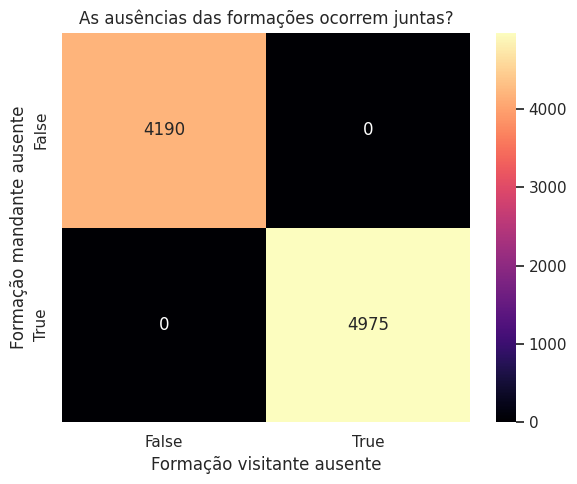

In [ ]:
# Verificando se os dados ausentes das formações acontecem juntos
tabela_contingencia = pd.crosstab(
    df["formacao_mandante"].isna(),
    df["formacao_visitante"].isna(),
    rownames=["Formação mandante ausente"],
    colnames=["Formação visitante ausente"]
)

fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    tabela_contingencia,
    annot=True,
    fmt="d",
    cmap="magma",
    ax=ax
)

ax.set_title("As ausências das formações ocorrem juntas?")

plt.tight_layout()
plt.show()

Pra discutir: 4.975 partidas possuem formacao_mandante e formacao_visitante ausentes ao mesmo tempo. Isso mostra que as ausências não parecem ser independentes entre as duas variáveis, pois as duas informações faltam nas mesmas partidas.

Porém, esse resultado sozinho não é suficiente para descartar a hipótese de MCAR, pois as duas informações podem ter ficado ausentes por causa de um mesmo processo de coleta ou registro dos dados, sem relação com os valores que deveriam estar preenchidos.

O padrão pode ser compatível com um mecanismo MAR, caso a ausência esteja relacionada a outras informações observadas nas partidas, como período, rodada ou data. Para confirmar melhor essa hipótese, seria necessário comparar a ocorrência das ausências com outras variáveis disponíveis no conjunto de dados.

Com essa análise, também não é possível afirmar que o mecanismo seja MNAR, pois não temos evidências de que a ausência esteja diretamente relacionada ao próprio valor da formação que deveria estar registrado.

Portanto, a análise mostra que existe um padrão de ausência conjunta entre formacao_mandante e formacao_visitante, mas não permite determinar sozinha se o mecanismo é MCAR, MAR ou MNAR. São necessárias outras análises para obter evidências mais fortes sobre o mecanismo de ausência.

## 3. Princípio Distribucional

Ainda com os dados originais do Campeonato Brasileiro, sem realizar o tratamento dos valores ausentes ou dos possíveis outliers, vou calcular algumas estatísticas descritivas e analisar a distribuição das variáveis numéricas presentes no conjunto de dados.

Essa etapa tem como objetivo obter um primeiro retrato dos dados antes da realização dos tratamentos. A partir das medidas como média, mediana, mínimo, máximo e desvio padrão, além da análise dos gráficos de distribuição, podemos identificar características importantes das variáveis, como concentração dos valores, dispersão, assimetria e possíveis valores extremos.

Essas informações serão utilizadas para orientar as decisões das próximas etapas. Por exemplo, caso uma variável apresente uma distribuição muito assimétrica ou possua valores extremos, a mediana pode ser uma medida mais adequada do que a média para representar os dados em determinadas análises.



In [ ]:
# Variáveis quantitativas e qualitativas

VARS_QUANT = [
    "rodata",
    "mandante_Placar",
    "visitante_Placar",
    "arrecadacao"
]

VARS_QUALI = [
    "mandante",
    "visitante",
    "resultado_mandante",
    "arena",
    "mandante_Estado",
    "visitante_Estado",
    "formacao_mandante",
    "formacao_visitante",
    "tecnico_mandante",
    "tecnico_visitante"
]

# Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T

desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(
        cmap="magma",
        subset=["skewness", "kurtosis"]
    )
)

,mean,median,std,min,max,skewness,kurtosis
rodata,20.08,20.00,11.41,1.00,46.00,0.05,-1.11
mandante_Placar,1.54,1.00,1.23,0.00,8.00,0.82,0.68
visitante_Placar,1.03,1.00,1.03,0.00,7.00,1.04,1.23
arrecadacao,1363329.52,996258.25,1158877.44,61875.00,5983920.00,1.29,1.46


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam no contexto do Campeonato Brasileiro? Por exemplo, os placares costumam ficar concentrados em valores baixos, enquanto a arrecadação pode apresentar alguns valores muito maiores que a maioria das partidas, formando uma cauda à direita?


resposta: Observando a tabela, as variáveis que apresentam skewness acima de 1 são visitante_Placar, com 1,04, e principalmente arrecadacao, com 1,29. Isso indica uma assimetria à direita, ou seja, existem alguns valores mais altos que puxam a distribuição para a direita.

A variável arrecadacao apresenta a maior assimetria, o que é coerente com o contexto do Campeonato Brasileiro, pois algumas partidas podem ter uma arrecadação muito maior que a maioria dos jogos, contribuindo para uma cauda mais longa à direita.

Em relação à kurtosis, nenhuma das variáveis apresentou valor maior que 2 em módulo. Portanto, não há indicação, por esse critério, de uma cauda extremamente pesada.

De forma geral, os resultados fazem sentido para os dados do futebol: os placares costumam ficar concentrados em valores baixos, enquanto a arrecadação pode variar bastante entre as partidas, com alguns jogos apresentando valores muito superiores aos demais.

Distribuições de dados

Onde fizer sentido, vou comparar as partidas em que o mandante venceu com aquelas em que o mandante não venceu. Essa divisão permite observar se existe diferença na distribuição de variáveis como os gols marcados pelo mandante, os gols marcados pelo visitante e a arrecadação das partidas.

vou utilizar uma convenção de cores para representar esses dois grupos e mantê-la nas análises seguintes, inclusive na análise bivariada.

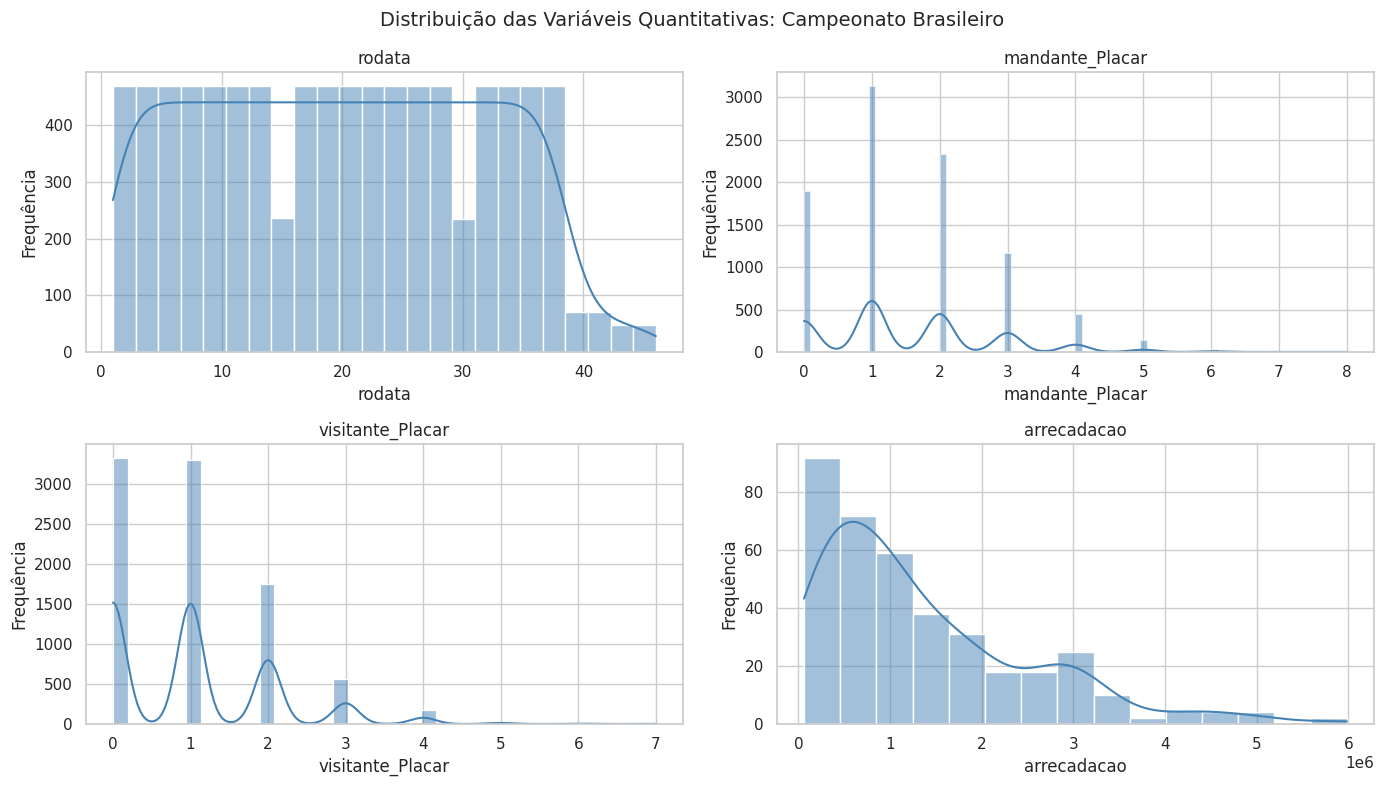

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        color="steelblue",
        ax=axes[i]
    )

    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequência")

fig.suptitle(
    "Distribuição das Variáveis Quantitativas: Campeonato Brasileiro",
    fontsize=14
)

plt.tight_layout()

plt.show()

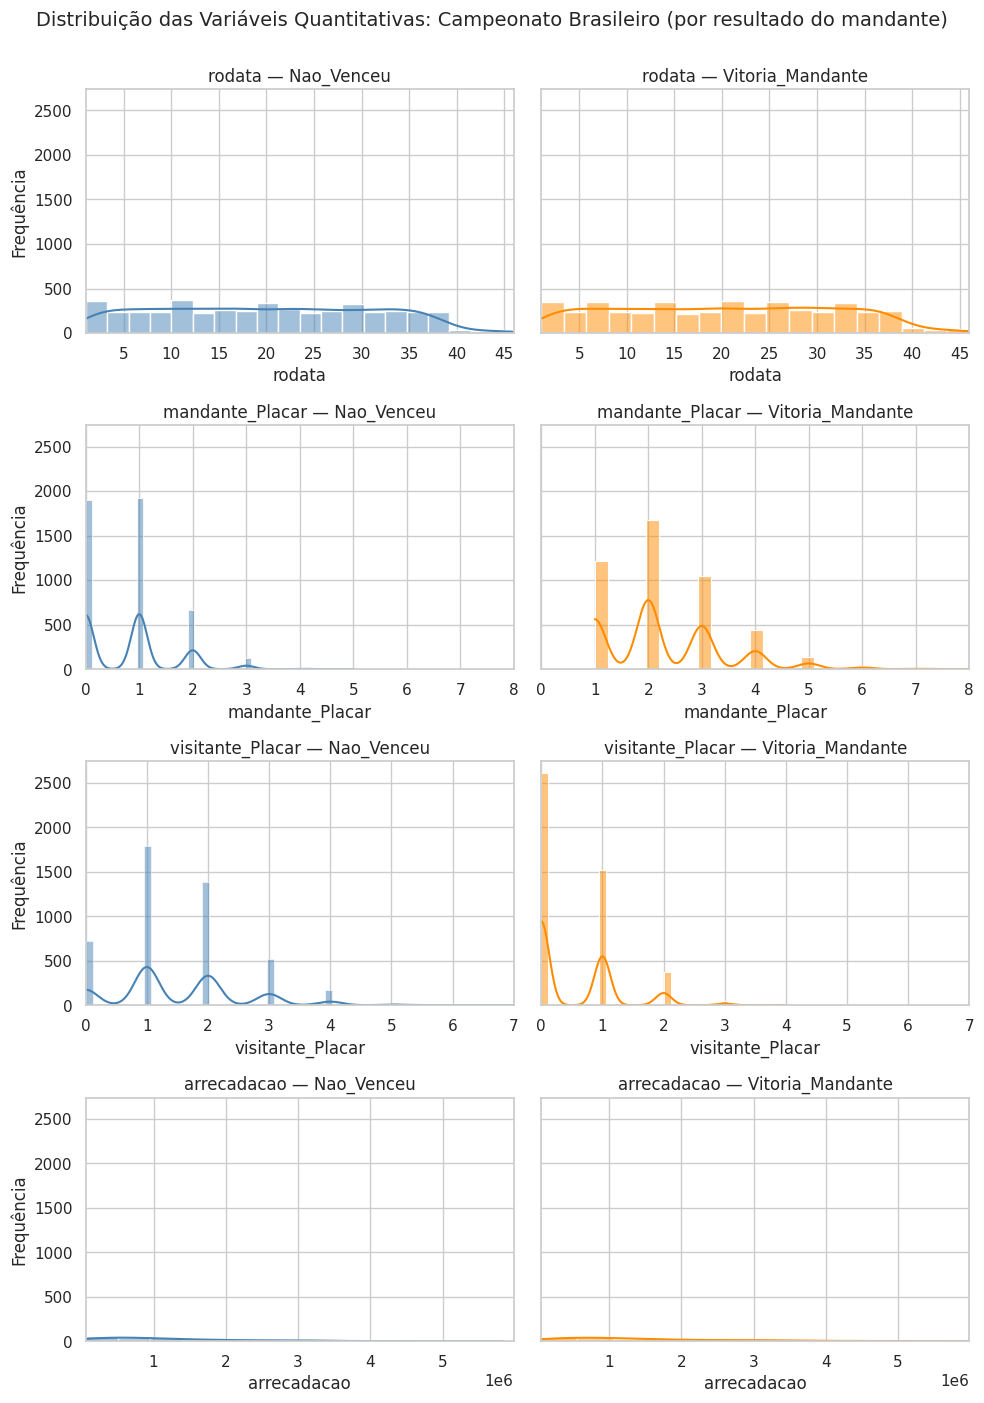

In [ ]:
fig, axes = plt.subplots(
    len(VARS_QUANT),
    2,
    figsize=(10, 3.5 * len(VARS_QUANT)),
    sharey=True
)

for i, col in enumerate(VARS_QUANT):

    lim = (df[col].min(), df[col].max())

    for j, (classe, cor) in enumerate([
        ("Nao_Venceu", "steelblue"),
        ("Vitoria_Mandante", "darkorange")
    ]):

        subset = df[df["resultado_mandante"] == classe]

        sns.histplot(
            data=subset,
            x=col,
            kde=True,
            color=cor,
            ax=axes[i, j]
        )

        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")
        axes[i, j].set_xlabel(col)
        axes[i, j].set_ylabel("Frequência")

fig.suptitle(
    "Distribuição das Variáveis Quantitativas: Campeonato Brasileiro (por resultado do mandante)",
    fontsize=14,
    y=1.001
)

plt.tight_layout()

plt.show()

**Para discutir:** agora que os resultados do mandante estão em painéis separados, mantendo a mesma escala do eixo X em cada linha, fica mais fácil comparar as distribuições. Alguma das variáveis apresenta um formato ou comportamento claramente diferente entre as partidas em que o **mandante venceu** e aquelas em que o **mandante não venceu**?



**Pra discutir:** Observando os gráficos, a variável que apresenta a diferença mais clara entre os grupos é `mandante_Placar`. Nas partidas em que o mandante venceu, os valores ficam mais concentrados em placares maiores, principalmente 1, 2 e 3 gols, enquanto nas partidas em que o mandante não venceu aparecem muitos resultados com 0 e 1 gol do mandante.

A variável `visitante_Placar` também apresenta uma diferença evidente. Nas partidas em que o mandante não venceu, os valores de gols do visitante são mais distribuídos entre 0, 1 e 2 gols. Já nas vitórias do mandante, o valor 0 para o visitante aparece com bastante frequência, indicando que muitas dessas partidas terminaram sem gols do time visitante.

Por outro lado, `rodata` apresenta um comportamento bastante semelhante nos dois grupos, com uma distribuição relativamente uniforme ao longo das rodadas. A `arrecadacao` também mantém um formato parecido entre os grupos, apresentando concentração em valores mais baixos e uma cauda à direita.

Portanto, as variáveis relacionadas ao **placar** apresentam as diferenças mais claras entre as partidas em que o mandante venceu e aquelas em que não venceu, enquanto `rodata` e `arrecadacao` possuem distribuições mais semelhantes entre os grupos.


#### Testes de Aderência

*Será que a arrecadação das partidas segue uma distribuição normal?*

O **Shapiro-Wilk** será utilizado como teste de aderência para verificar a normalidade da variável `arrecadacao`, juntamente com o **QQ-Plot** como visualização de apoio. Essa análise ajudará a verificar se os valores observados se aproximam de uma distribuição normal e poderá auxiliar nas decisões das próximas etapas da análise dos dados.


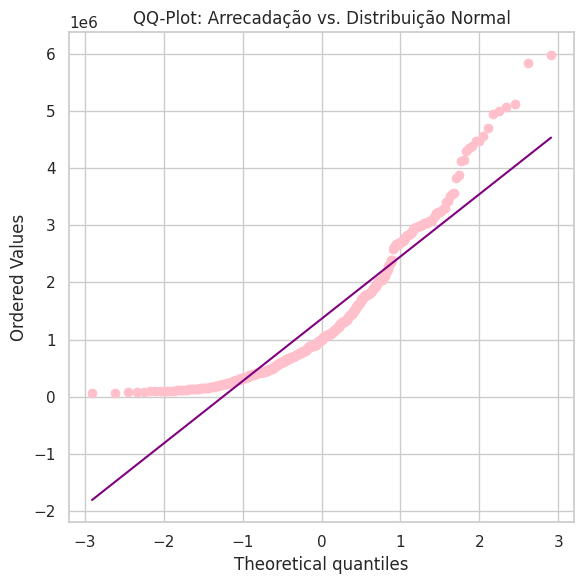

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))

stats.probplot(
    df["arrecadacao"].dropna(),
    dist="norm",
    plot=ax
)

ax.get_lines()[0].set_markerfacecolor("pink")
ax.get_lines()[0].set_markeredgecolor("pink")

ax.get_lines()[1].set_color("purple")

ax.set_title("QQ-Plot: Arrecadação vs. Distribuição Normal")

plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguirem a reta de referência de perto, a variável `arrecadacao` apresenta um comportamento próximo de uma distribuição normal. Quando os pontos se afastam da reta, principalmente nas extremidades, isso indica que a distribuição dos valores observados apresenta diferenças em relação à distribuição normal, podendo indicar caudas mais pesadas ou mais leves.

**Nota: cuidado com duas armadilhas de interpretação**

* **Tamanho da amostra e poder do teste:** o tamanho da amostra influencia bastante o resultado do teste de Shapiro-Wilk. Amostras pequenas possuem menos poder estatístico e podem não rejeitar a normalidade mesmo quando existem desvios. Já amostras muito grandes, como no nosso conjunto de dados, podem fazer o teste detectar até pequenas diferenças em relação à distribuição normal. Como o Campeonato Brasileiro possui milhares de partidas, o resultado do teste deve ser analisado junto com o QQ-Plot e as medidas de assimetria (`skewness`), evitando interpretar o p-valor de forma isolada.

* **Como afirmar o resultado:** quando o teste de Shapiro-Wilk **rejeita** a hipótese nula (p < 0,05), temos evidência estatística **contra a normalidade** da variável `arrecadacao`. Quando o teste **não rejeita** a hipótese nula (p ≥ 0,05), não significa que podemos afirmar que os dados são normais; significa apenas que não encontrei evidência estatística suficiente para rejeitar a normalidade.


**Resposta:** No QQ-Plot da variável `arrecadacao`, podemos observar que os pontos apresentam um afastamento considerável da reta de referência, principalmente nas extremidades. Isso indica que a distribuição dos valores de arrecadação apresenta diferenças em relação a uma distribuição normal.

O afastamento é mais evidente nos valores extremos, mostrando a presença de uma cauda à direita. Esse comportamento também é coerente com a `skewness` de **1,29**, que indica assimetria positiva na distribuição da arrecadação.

Além disso, o resultado do teste de Shapiro-Wilk apresentou `p < 0,05`, levando à rejeição da hipótese de normalidade. Nesse teste, foram considerados apenas os valores disponíveis de `arrecadacao`, pois os valores ausentes foram ignorados com `dropna()`. Portanto, a análise não utiliza todas as 9.165 partidas.

Assim, tanto o QQ-Plot quanto as medidas estatísticas indicam que a variável `arrecadacao` **não apresenta um comportamento próximo de uma distribuição normal**, principalmente devido à sua assimetria e aos valores elevados presentes na cauda direita.


In [ ]:
resultados_shapiro = []

for col in VARS_QUANT:

    stat, p = stats.shapiro(df[col].dropna())

    resultados_shapiro.append({
        "variavel": col,
        "estatistica": round(stat, 4),
        "p_valor": round(p, 6),
        "rejeita_normalidade": p < 0.05
    })

pd.DataFrame(resultados_shapiro).set_index("variavel")

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 9165.
  res = hypotest_fun_out(*samples, **kwds)


,estatistica,p_valor,rejeita_normalidade
variavel,,,
rodata,0.9632,0.0,True
mandante_Placar,0.8923,0.0,True
visitante_Placar,0.8347,0.0,True
arrecadacao,0.8748,0.0,True


### Interpretação dos testes de Shapiro-Wilk

Os testes de Shapiro-Wilk indicaram rejeição da hipótese nula de normalidade para todas as variáveis quantitativas analisadas. As variáveis `rodata`, `mandante_Placar`, `visitante_Placar` e `arrecadacao` apresentaram p-valores inferiores a 0,05, indicando evidência estatística contra a normalidade dessas distribuições.

É importante considerar o tamanho da amostra ao interpretar esses resultados. O dataset possui 9.165 partidas, mas cada teste utiliza apenas os valores não ausentes da respectiva variável. Isso é especialmente importante para `arrecadacao`, que possui muitos valores faltantes e, portanto, teve uma quantidade bem menor de observações utilizadas no teste.

Além do p-valor, também considerei os histogramas, o QQ-Plot e as medidas de assimetria. Dessa forma, os resultados do Shapiro-Wilk são analisados junto com as características visuais e estatísticas das distribuições, evitando tirar uma conclusão apenas com base no teste.


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende da escolha do número de bins. Para cada valor no eixo X, a curva mostra a **proporção acumulada** de partidas com valores menores ou iguais àquele valor.

Essa visualização é especialmente útil para entender o comportamento de uma variável e comparar diferentes grupos. Quando duas curvas são apresentadas juntas, os pontos em que elas se distanciam mais indicam regiões onde as distribuições apresentam maiores diferenças.

vou utilizar a variável `arrecadacao` como exemplo para observar como essa visualização funciona no conjunto de dados do Campeonato Brasileiro.


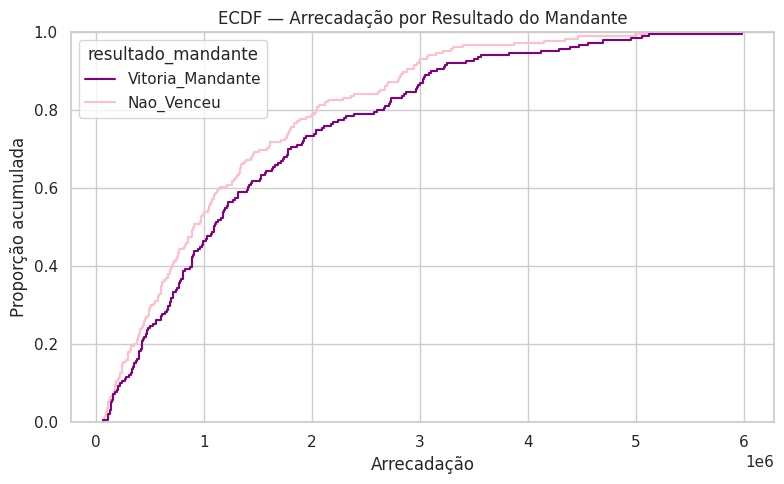

In [ ]:
plt.figure(figsize=(8, 5))

sns.ecdfplot(
    data=df,
    x="arrecadacao",
    hue="resultado_mandante",
    palette={
        "Nao_Venceu": "pink",
        "Vitoria_Mandante": "purple"
    }
)

plt.title("ECDF — Arrecadação por Resultado do Mandante")
plt.xlabel("Arrecadação")
plt.ylabel("Proporção acumulada")

plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva indica **qual proporção das partidas daquele grupo possui arrecadação menor ou igual àquele valor**.

Onde as duas curvas (rosa e roxa) apresentam maior distância, temos uma faixa de arrecadação em que os dois grupos — **partidas em que o mandante não venceu** e **partidas em que o mandante venceu** — apresentam maior diferença na distribuição.

Uma vantagem da ECDF é que essa comparação pode ser feita sem precisar definir uma quantidade ou largura de bins, como acontece no histograma.


**Como interpretar o gráfico:** A ECDF mostra uma diferença entre as distribuições de arrecadação das partidas em que o mandante venceu e das partidas em que não venceu. A curva de `Nao_Venceu` fica acima da curva de `Vitoria_Mandante` durante grande parte da distribuição, principalmente entre aproximadamente R$ 500 mil e R$ 2 milhões.

Isso indica que, nessa faixa, uma proporção maior das partidas em que o mandante não venceu possui arrecadação menor ou igual ao valor analisado. A maior distância entre as curvas aparece aproximadamente entre R$ 800 mil e R$ 1,3 milhão, indicando que essa é uma das regiões em que as distribuições apresentam maior diferença.

Nas arrecadações mais altas, as curvas se aproximam, mostrando que a diferença entre os grupos diminui. Portanto, a ECDF sugere que as partidas em que o mandante venceu tendem a apresentar uma distribuição de arrecadação um pouco mais alta em boa parte da faixa analisada, embora exista bastante sobreposição entre os dois grupos.

Uma vantagem da ECDF é permitir essa comparação de forma direta, sem depender da escolha de bins como acontece no histograma.


### Métricas de Tendêncial Central

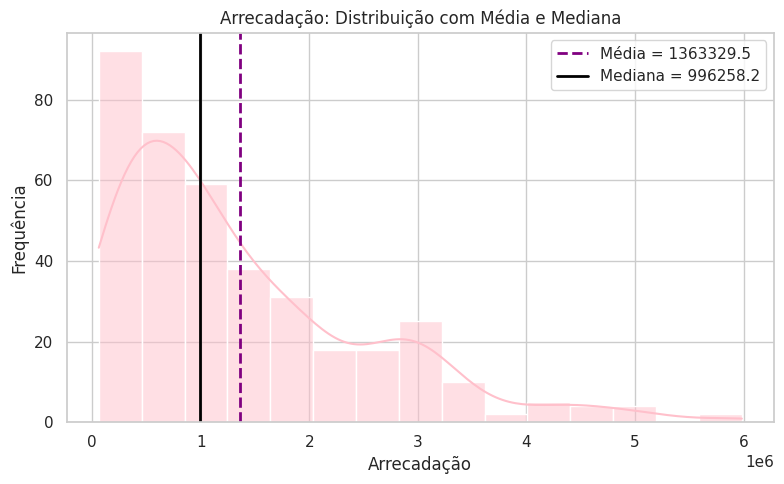

In [ ]:
media_arrecadacao = df["arrecadacao"].mean()

mediana_arrecadacao = df["arrecadacao"].median()

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="arrecadacao",
    kde=True,
    color="pink"
)

plt.axvline(
    media_arrecadacao,
    color="purple",
    linestyle="--",
    linewidth=2,
    label=f"Média = {media_arrecadacao:.1f}"
)

plt.axvline(
    mediana_arrecadacao,
    color="black",
    linestyle="-",
    linewidth=2,
    label=f"Mediana = {mediana_arrecadacao:.1f}"
)

plt.title("Arrecadação: Distribuição com Média e Mediana")
plt.xlabel("Arrecadação")
plt.ylabel("Frequência")

plt.legend()

plt.tight_layout()
plt.show()

### Dispersão

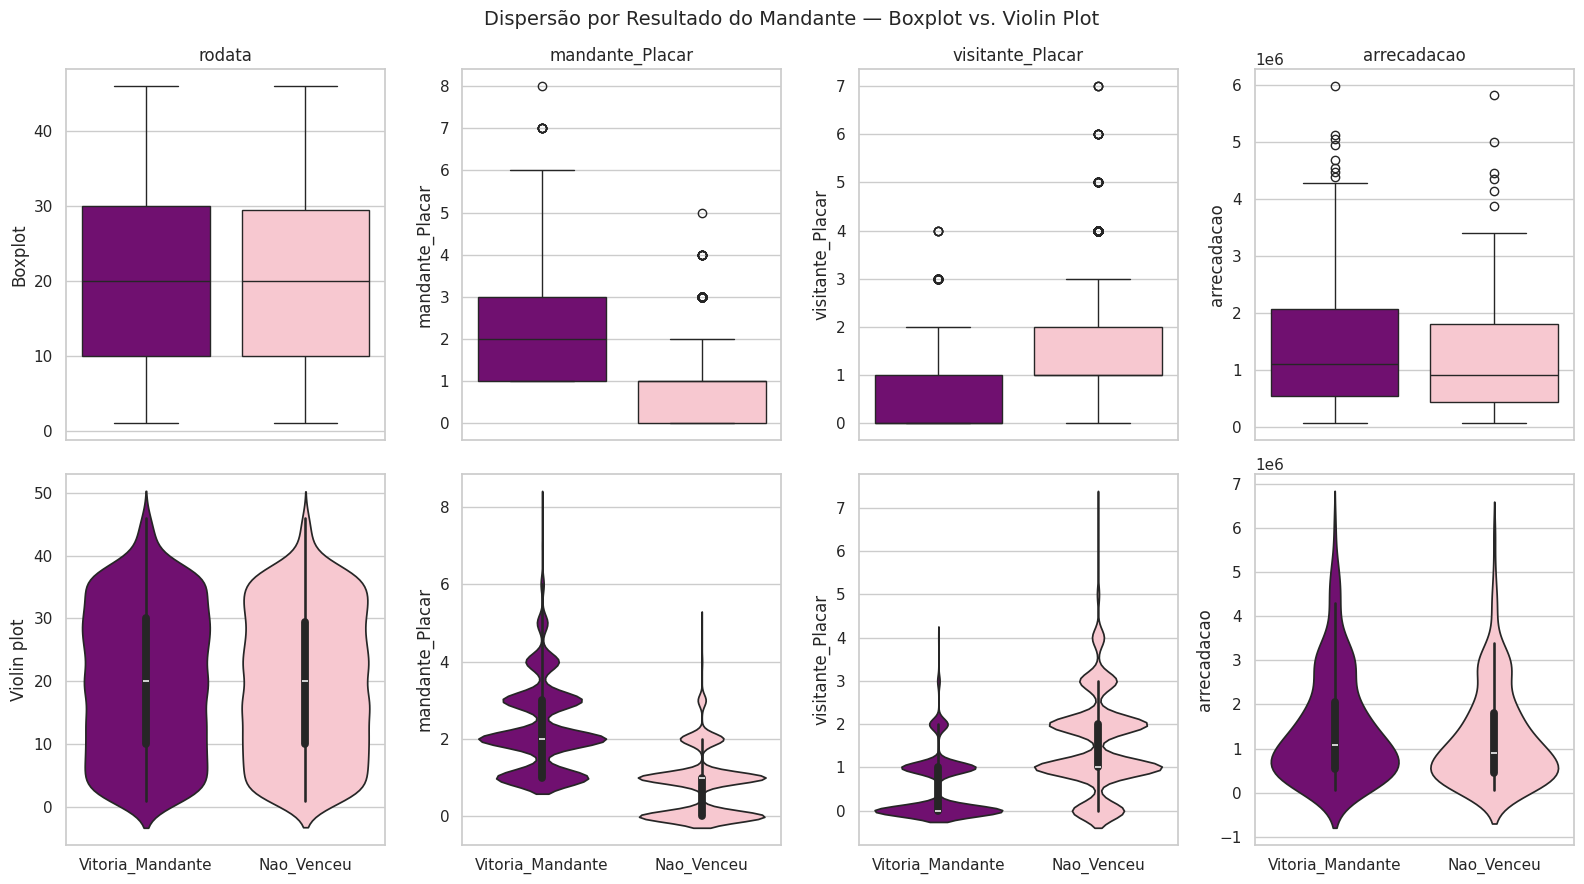

In [ ]:
palette_classe = {
    "Nao_Venceu": "pink",
    "Vitoria_Mandante": "purple"
}

fig, axes = plt.subplots(
    2,
    len(VARS_QUANT),
    figsize=(4 * len(VARS_QUANT), 9),
    sharex="col"
)

for i, col in enumerate(VARS_QUANT):

    sns.boxplot(
        data=df,
        x="resultado_mandante",
        y=col,
        hue="resultado_mandante",
        palette=palette_classe,
        legend=False,
        ax=axes[0, i]
    )

    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(
        data=df,
        x="resultado_mandante",
        y=col,
        hue="resultado_mandante",
        palette=palette_classe,
        legend=False,
        ax=axes[1, i]
    )

    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")

fig.suptitle(
    "Dispersão por Resultado do Mandante — Boxplot vs. Violin Plot",
    fontsize=14
)

plt.tight_layout()
plt.show()

Pra discutir: alguma variável apresenta uma diferença clara no intervalo interquartil (IQR) entre as partidas em que o mandante venceu e aquelas em que o mandante não venceu? Essa diferença pode indicar que a variável ajuda a diferenciar os dois resultados?

**Pra discutir:** A variável que apresenta a diferença mais clara entre os grupos é `mandante_Placar`. No boxplot, as partidas em que o mandante venceu apresentam um intervalo interquartil maior e concentrado em valores mais altos, principalmente entre aproximadamente 1 e 3 gols. Já nas partidas em que o mandante não venceu, os valores ficam mais concentrados entre 0 e 1 gol.

`visitante_Placar` também apresenta uma diferença entre os grupos. Nas vitórias do mandante, os valores do placar do visitante ficam mais concentrados em valores baixos, enquanto nas partidas em que o mandante não venceu existe maior ocorrência de valores mais altos do visitante.

A variável `rodata` apresenta caixas muito semelhantes entre os dois grupos, indicando pouca diferença na dispersão. A `arrecadacao` apresenta alguma diferença, mas as caixas possuem bastante sobreposição.

Portanto, o `mandante_Placar` é a variável que mais se destaca no boxplot e já apresenta um forte indício de que pode ajudar a diferenciar as partidas em que o mandante venceu das partidas em que não venceu.


4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos as informações necessárias para decidir como tratar os dados ausentes e os outliers das variáveis quantitativas. Nesta seção, vou identificar os valores considerados outliers pela regra do IQR e analisar se eles representam possíveis erros ou apenas valores extremos que fazem sentido no contexto das partidas. Depois do tratamento, vou rodar a estatística descritiva novamente ("depois") para verificar o efeito das escolhas e fechar o ciclo iterativo que comecei na abertura.

Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de [Q1 - 1.5*IQR, Q3 + 1.5*IQR].

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1

    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


resumo_outliers = {}

for col in VARS_QUANT:

    lim_inf, lim_sup = limites_iqr(df[col])

    n_outliers = (
        (df[col] < lim_inf) |
        (df[col] > lim_sup)
    ).sum()

    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers
    }


pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
rodata,-20.00,60.00,0.0
mandante_Placar,-0.50,3.50,632.0
visitante_Placar,-3.00,5.00,11.0
arrecadacao,-1691303.31,4080650.19,15.0


### Visualizando os Outliers

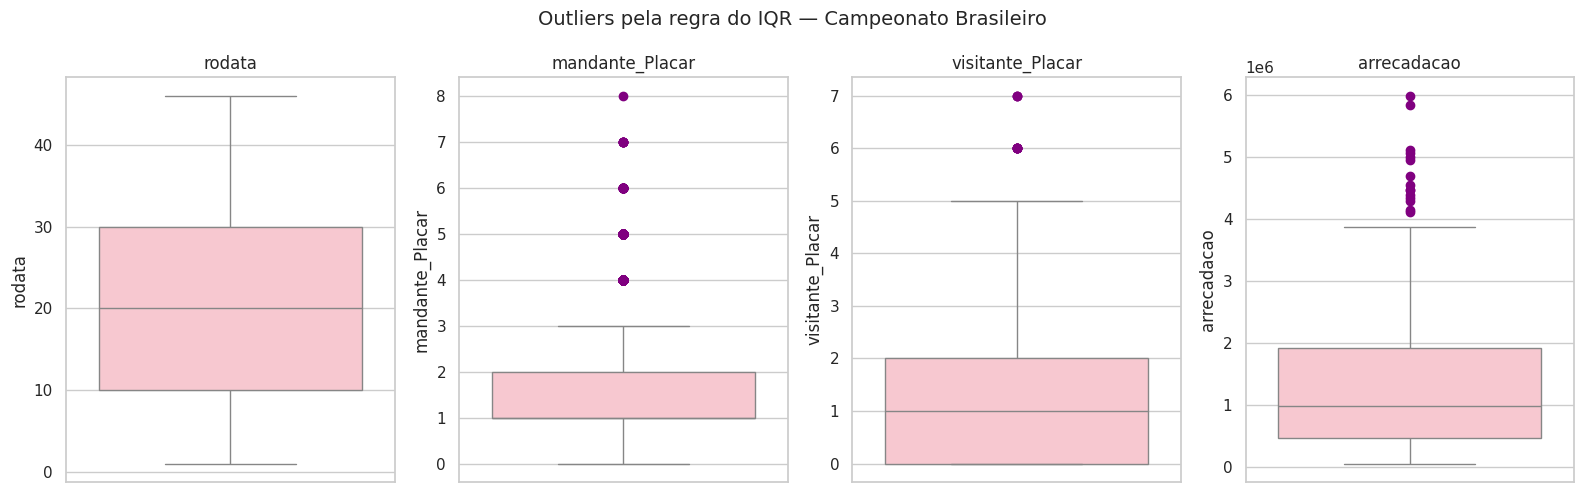

In [ ]:
fig, axes = plt.subplots(
    1,
    len(VARS_QUANT),
    figsize=(4 * len(VARS_QUANT), 5)
)

for i, col in enumerate(VARS_QUANT):

    sns.boxplot(
        data=df,
        y=col,
        color="pink",
        flierprops=dict(
            markerfacecolor="purple",
            markeredgecolor="purple",
            marker="o"
        ),
        ax=axes[i]
    )

    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].set_ylabel(col)

fig.suptitle(
    "Outliers pela regra do IQR — Campeonato Brasileiro",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [ ]:
for col in VARS_QUANT:

    lim_inf, lim_sup = limites_iqr(df[col])

    outliers = df[
        (df[col] < lim_inf) |
        (df[col] > lim_sup)
    ][col]

    print(f"\n{col}")
    print(f"Limite inferior: {lim_inf:.2f}")
    print(f"Limite superior: {lim_sup:.2f}")
    print(f"Quantidade de outliers: {len(outliers)}")
    print(f"Menor outlier: {outliers.min()}")
    print(f"Maior outlier: {outliers.max()}")


rodata
Limite inferior: -20.00
Limite superior: 60.00
Quantidade de outliers: 0
Menor outlier: nan
Maior outlier: nan

mandante_Placar
Limite inferior: -0.50
Limite superior: 3.50
Quantidade de outliers: 632
Menor outlier: 4
Maior outlier: 8

visitante_Placar
Limite inferior: -3.00
Limite superior: 5.00
Quantidade de outliers: 11
Menor outlier: 6
Maior outlier: 7

arrecadacao
Limite inferior: -1691303.31
Limite superior: 4080650.19
Quantidade de outliers: 15
Menor outlier: 4117072.5
Maior outlier: 5983920.0


**Pra discutir:** Os outliers encontrados nas variáveis quantitativas parecem ser, em sua maioria, valores estatisticamente extremos, mas que são possíveis dentro do contexto do Campeonato Brasileiro.

Nos casos de `mandante_Placar` e `visitante_Placar`, valores elevados de gols são pouco frequentes, mas são possíveis em uma partida de futebol. Portanto, um placar considerado outlier pela regra do IQR não significa necessariamente que seja um erro de dados. Por exemplo, partidas com muitos gols podem realmente acontecer.

Na variável `arrecadacao`, também existem valores muito acima da maior parte dos dados. Porém, uma arrecadação elevada é possível em partidas com maior público, maior importância ou maior movimentação financeira. Dessa forma, esses valores não violam nenhuma condição física ou regra de negócio conhecida.

A variável `rodata` também possui valores dentro de um intervalo possível para as rodadas do campeonato, portanto não há indicação de valores fisicamente impossíveis.

Assim, os outliers encontrados parecem se encaixar principalmente na categoria de **outliers estatísticos legítimos**, e não em erros de dados ou violações de domínio. Por isso, a princípio, não devemos simplesmente remover essas observações. O mais adequado é **mantê-las** e, caso alguma análise estatística seja muito influenciada pelos valores extremos, considerar métodos ou transformações mais robustas.


Pra discutir: considerando a quantidade de dados ausentes nas variáveis formacao_mandante e formacao_visitante e o fato de essas ausências ocorrerem juntas em muitas partidas, é adequado remover essas linhas ou seria melhor manter as partidas e identificar as formações ausentes como "Nao informado"?

In [ ]:
linhas_antes = df.shape[0]

df_antes = df.copy()

# Como as formações são variáveis categóricas,
# os valores ausentes serão identificados como "Nao informado"
df["formacao_mandante"] = df["formacao_mandante"].fillna("Nao informado")
df["formacao_visitante"] = df["formacao_visitante"].fillna("Nao informado")
df["tecnico_mandante"] = df["tecnico_mandante"].fillna("Nao informado")
df["tecnico_visitante"] = df["tecnico_visitante"].fillna("Nao informado")
linhas_depois = df.shape[0]

print(
    f"Linhas antes: {linhas_antes} | "
    f"Linhas depois: {linhas_depois} | "
    f"Removidas: {linhas_antes - linhas_depois}"
)

Linhas antes: 9165 | Linhas depois: 9165 | Removidas: 0


Assim como fiz com formacao_mandante e formacao_visitante, optei por substituir os valores ausentes de
tecnico_mandante e tecnico_visitante por "Nao informado", pelo mesmo motivo: são variáveis categóricas e
remover essas linhas causaria perda significativa de dados (4.610 partidas).

Já a variável arrecadacao foi mantida com os valores ausentes (NaN), sem imputação, pois se trata de uma
variável numérica contínua com forte assimetria e apenas 380 registros preenchidos — imputar um valor
único (como média ou mediana) para mais de 8 mil registros distorceria significativamente a distribuição
real da variável.

No nosso conjunto de dados, as variáveis `formacao_mandante` e `formacao_visitante` apresentam uma quantidade considerável de valores ausentes. Além disso, verifiquei que as duas informações estão ausentes simultaneamente em muitas partidas.

Por esse motivo, não seria adequado remover todas as linhas afetadas, pois isso resultaria em uma perda muito grande de informações do conjunto de dados. Como as formações são variáveis categóricas e a ausência não significa necessariamente que a partida seja inválida, optei por manter todas as partidas e substituir os valores ausentes por `"Nao informado"`.

Dessa forma, nenhuma linha foi removida e todas as partidas foram preservadas para as demais análises. O tratamento realizado foi aplicado somente às variáveis de formação, deixando explícito que essa informação não estava disponível no conjunto de dados original.


### Decisão sobre o tratamento dos outliers

Os outliers encontrados nas variáveis quantitativas serão mantidos, pois os valores identificados não parecem representar erros de coleta ou valores impossíveis dentro do contexto do Campeonato Brasileiro.

Nos placares, valores elevados são raros, mas podem acontecer em partidas reais. Da mesma forma, valores altos de `arrecadacao` podem representar partidas que tiveram uma arrecadação muito superior à maioria dos jogos.

Dessa forma, classifiquei esses casos principalmente como **outliers estatísticos legítimos**. A decisão será manter os valores originais, pois removê-los poderia eliminar informações reais do conjunto de dados.

Entretanto, como a variável `arrecadacao` apresenta uma assimetria positiva (`skewness = 1,29`), uma transformação logarítmica pode ser útil em análises futuras caso seja necessário reduzir a influência dos valores muito altos. Essa transformação será apenas uma alternativa para análises específicas, sem substituir os valores originais do dataset.


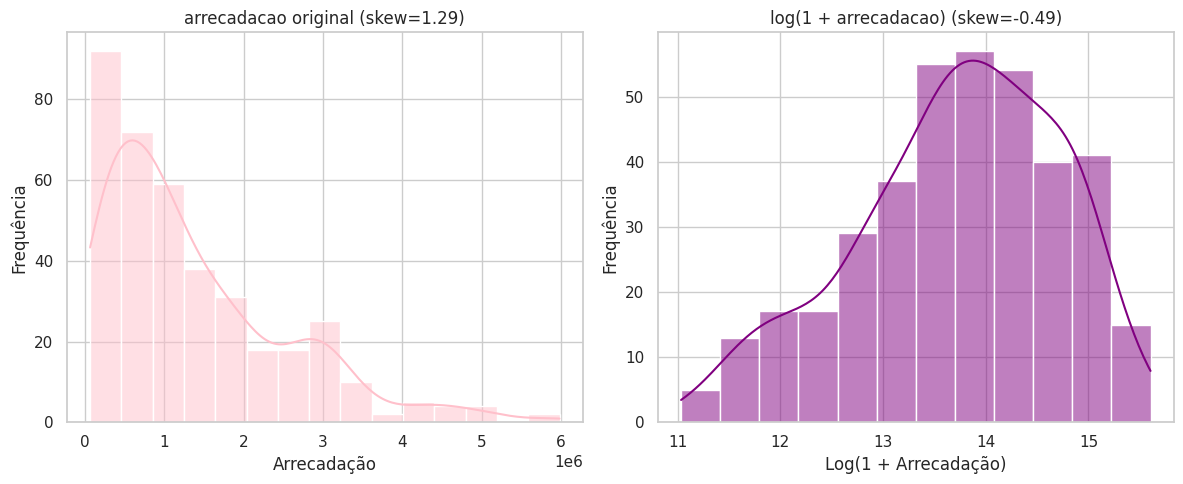

In [ ]:
import numpy as np

df["arrecadacao_log"] = np.log1p(df["arrecadacao"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    data=df,
    x="arrecadacao",
    kde=True,
    color="pink",
    ax=axes[0]
)

axes[0].set_title(
    f"arrecadacao original (skew={df['arrecadacao'].skew():.2f})"
)

axes[0].set_xlabel("Arrecadação")
axes[0].set_ylabel("Frequência")

sns.histplot(
    data=df,
    x="arrecadacao_log",
    kde=True,
    color="purple",
    ax=axes[1]
)

axes[1].set_title(
    f"log(1 + arrecadacao) (skew={df['arrecadacao_log'].skew():.2f})"
)

axes[1].set_xlabel("Log(1 + Arrecadação)")
axes[1].set_ylabel("Frequência")

plt.tight_layout()

plt.show()

Pra discutir: a transformação logarítmica reduziu visivelmente a assimetria da arrecadação? Mantivemos arrecadacao_log somente como demonstração, mas não vou utilizá-la nas próximas seções. A ideia foi mostrar que essa transformação pode ser uma opção quando o objetivo for reduzir a assimetria de uma variável e, por exemplo, utilizar um teste paramétrico que tenha como requisito uma distribuição mais próxima da normalidade.

Sim. A transformação logarítmica reduziu bastante a assimetria da variável arrecadacao. Na distribuição original, a assimetria era de 1,29, indicando uma cauda mais longa à direita. Após aplicar log(1 + arrecadacao), a assimetria passou para -0,49, deixando a distribuição visualmente mais equilibrada. Portanto, a transformação foi eficiente para diminuir a assimetria da arrecadação. Mesmo assim, arrecadacao_log será mantida apenas como demonstração e não será utilizada nas próximas análises.

Nota: nem todo outlier encontrado no Campeonato Brasileiro deve ser removido. Antes de tomar essa decisão, é necessário verificar se o valor é estatisticamente raro, mas ainda plausível, como uma arrecadação muito alta ou um placar elevado. Nesses casos, o valor pode ser mantido ou transformado. Se o valor violar alguma regra do contexto dos dados, deve ser investigado. Já valores que claramente representam erro de digitação ou de coleta podem ser corrigidos ou removidos.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratei os ausentes e decidimos manter os outliers. Agora rodei a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T

desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
rodata,20.08,20.00,11.41,1.00,46.00,0.05,-1.11
mandante_Placar,1.54,1.00,1.23,0.00,8.00,0.82,0.68
visitante_Placar,1.03,1.00,1.03,0.00,7.00,1.04,1.23
arrecadacao,1363329.52,996258.25,1158877.44,61875.00,5983920.00,1.29,1.46


### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})

comparacao["delta_skewness"] = (
    comparacao["skewness_depois"] - comparacao["skewness_antes"]
).round(3)

comparacao["delta_kurtosis"] = (
    comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]
).round(3)

comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
rodata,0.054,0.054,-1.107,-1.107,0.0,0.0
mandante_Placar,0.821,0.821,0.677,0.677,0.0,0.0
visitante_Placar,1.037,1.037,1.234,1.234,0.0,0.0
arrecadacao,1.293,1.293,1.457,1.457,0.0,0.0


**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que não removemos nenhuma linha e decidimos não alterar os outliers? Esse resultado, com pouca ou nenhuma mudança, é coerente com o tratamento conservador realizado?


Os valores não mudaram. Comparando as estatísticas antes e depois do tratamento, todas as variáveis apresentaram delta de skewness e kurtosis igual a 0,0. Isso significa que a assimetria e a curtose permaneceram exatamente iguais em todas as variáveis.

Essa pouca mudança era esperada, pois não removemos nenhuma linha do dataset e decidimos não alterar os outliers. Portanto, não fazia sentido esperar uma diferença grande nas estatísticas quantitativas. O resultado mostra que o tratamento foi conservador, preservando os dados originais e evitando alterações desnecessárias nos valores. Mesmo com pouca mudança nas estatísticas, o tratamento foi útil, pois os valores ausentes foram analisados e tratados adequadamente, enquanto os outliers foram avaliados antes de serem mantidos.

A arrecadação ainda rejeita normalidade?

vou rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [ ]:
from scipy import stats

# Teste de Shapiro-Wilk após o tratamento dos dados
arrecadacao_tratada = df["arrecadacao"].dropna()

stat_sw_depois, p_valor_sw_depois = stats.shapiro(arrecadacao_tratada)

print(
    f"Shapiro-Wilk (depois) — arrecadacao: "
    f"estatística={stat_sw_depois:.4f}, "
    f"p-valor={p_valor_sw_depois:.4g}"
)

# Interpretação do resultado
if p_valor_sw_depois < 0.05:
    print("Conclusão: a arrecadação ainda rejeita a hipótese de normalidade (p < 0,05).")
else:
    print("Conclusão: não rejeitei a hipótese de normalidade (p >= 0,05).")

Shapiro-Wilk (depois) — arrecadacao: estatística=0.8748, p-valor=5.461e-17
Conclusão: a arrecadação ainda rejeita a hipótese de normalidade (p < 0,05).


### Visualizando "antes" x "depois"

Para verificar o efeito do tratamento dos valores ausentes e dos outliers, podemos comparar a distribuição de algumas variáveis antes e depois do tratamento.

No nosso caso, nenhuma linha foi removida do conjunto de dados. Os valores ausentes das variáveis `formacao_mandante` e `formacao_visitante` foram substituídos por `"Nao informado"`.

Além disso, os outliers identificados nas variáveis quantitativas foram mantidos, pois não encontrei evidências de que esses valores fossem erros de registro. Dessa forma, a comparação antes e depois permite verificar se o tratamento realizado alterou a distribuição dos dados.


/tmp/ipykernel_15109/3436785006.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(["Antes", "Depois"])
/tmp/ipykernel_15109/3436785006.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(["Antes", "Depois"])


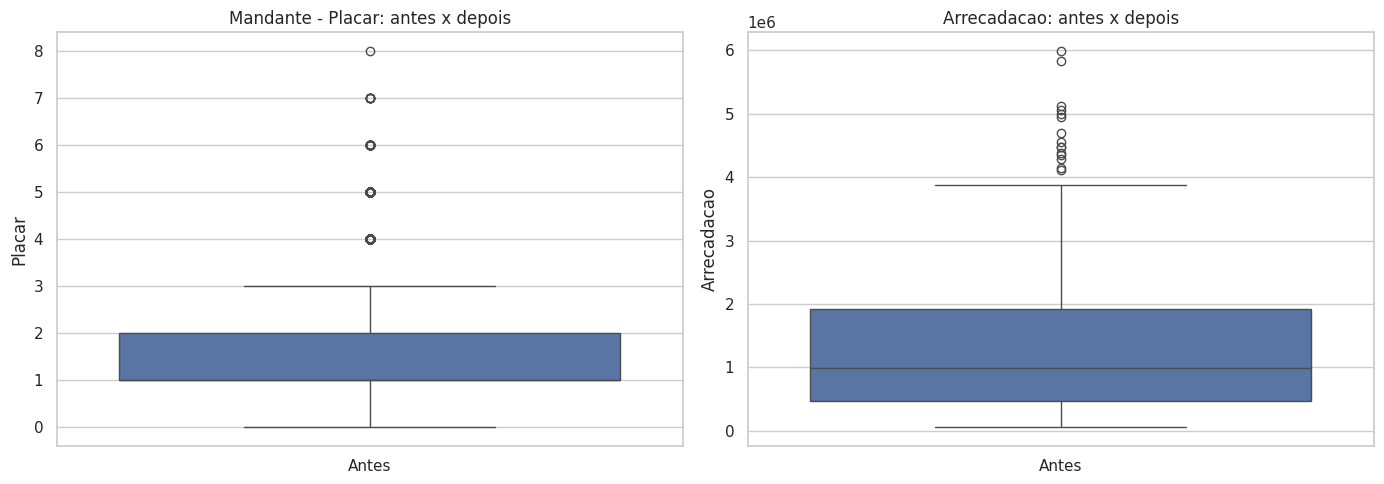

In [ ]:
# Comparação antes x depois

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Mandante - Placar

sns.boxplot(
data=[df_antes["mandante_Placar"].dropna(),
df["mandante_Placar"].dropna()],
ax=axes[0]
)

axes[0].set_xticklabels(["Antes", "Depois"])
axes[0].set_title("Mandante - Placar: antes x depois")
axes[0].set_ylabel("Placar")

# Arrecadacao

sns.boxplot(
data=[df_antes["arrecadacao"].dropna(),
df["arrecadacao"].dropna()],
ax=axes[1]
)

axes[1].set_xticklabels(["Antes", "Depois"])
axes[1].set_title("Arrecadacao: antes x depois")
axes[1].set_ylabel("Arrecadacao")

plt.tight_layout()
plt.show()


Pra discutir: as curvas "antes" e "depois" praticamente se sobrepõem? Sim. Nos dois gráficos, as curvas de `mandante_Placar` e `arrecadacao` ficaram praticamente sobrepostas, mostrando que não houve mudança significativa na distribuição dos dados após o tratamento. Isso era esperado, pois não removemos nenhuma linha e decidimos manter os outliers. A comparação confirma visualmente o que já foi observado nas estatísticas descritivas: o tratamento foi conservador e preservou os valores originais das variáveis quantitativas.

Essa verificação é importante porque permite confirmar visualmente se o tratamento realizado realmente teve o efeito esperado, em vez de assumir que houve uma mudança apenas por ter aplicado algum procedimento. Em conjuntos de dados com uma quantidade maior de valores ausentes ou outliers tratados, essa comparação poderia apresentar diferenças mais visíveis.


## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:

    freq_abs = df[col].value_counts()

    freq_rel = df[col].value_counts(normalize=True).round(3)

    print(f"\n--- {col} ---")

    print(
        pd.concat(
            [
                freq_abs.rename("absoluta"),
                freq_rel.rename("relativa")
            ],
            axis=1
        )
    )


--- mandante ---
                 absoluta  relativa
mandante                           
Fluminense            447     0.049
Sao Paulo             447     0.049
Flamengo              446     0.049
Corinthians           428     0.047
Atletico-MG           428     0.047
Santos                428     0.047
Internacional         428     0.047
Athletico-PR          409     0.045
Gremio                407     0.044
Palmeiras             405     0.044
Cruzeiro              390     0.043
Botafogo-RJ           387     0.042
Vasco                 352     0.038
Goias                 295     0.032
Coritiba              295     0.032
Bahia                 251     0.027
Vitoria               236     0.026
Sport                 228     0.025
Figueirense           219     0.024
Fortaleza             196     0.021
Juventude             181     0.020
Ponte Preta           181     0.020
Ceara                 152     0.017
Atletico-GO           152     0.017
Avai                  133     0.015
Chapecoens

#### Visualizando as frequências

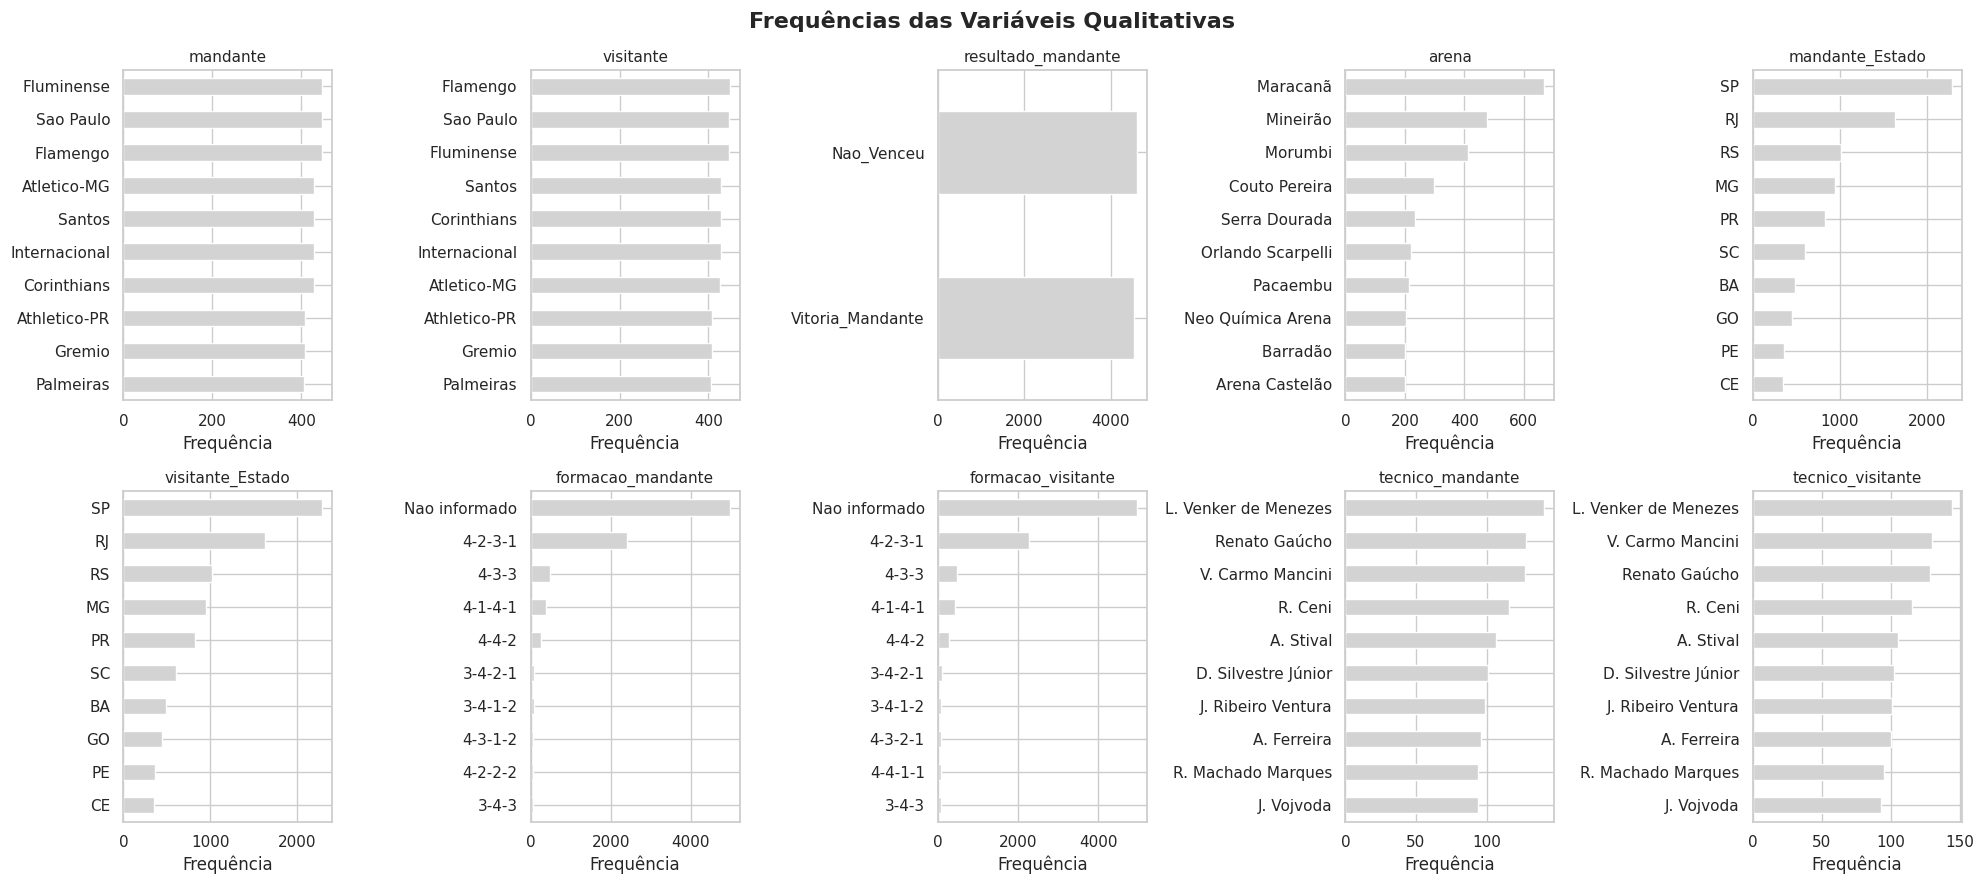

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 9), sharey=False)

axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):

    df[col].value_counts().head(10).sort_values().plot(
        kind="barh",
        color=COR_NEUTRA,
        ax=axes[i]
    )

    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel("Frequência")
    axes[i].set_ylabel("")

fig.suptitle(
    "Frequências das Variáveis Qualitativas",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vou interpretar cruzamentos com essa variável mais na frente na análise bivariada.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

vou aplicar as duas métricas às variáveis qualitativas, incluindo a variável alvo `resultado_mandante`.


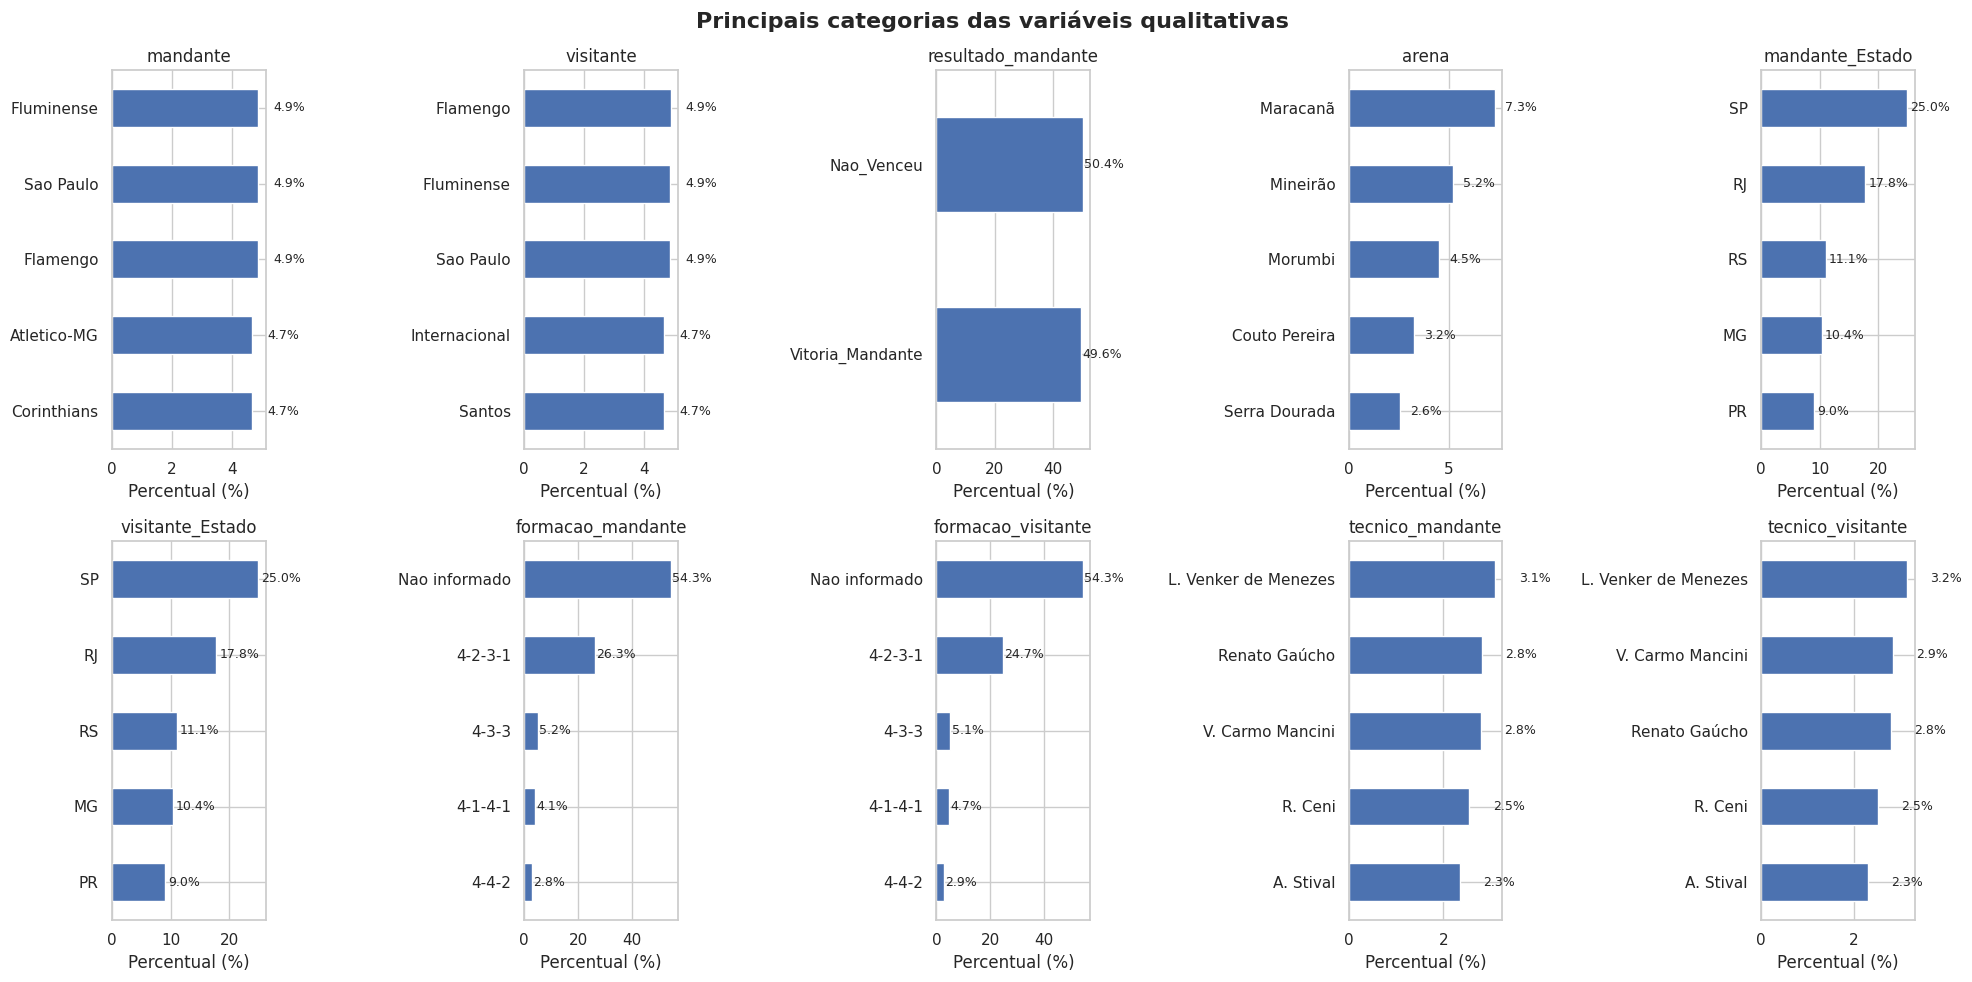

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 10))

axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):

    frequencias = df[col].value_counts(normalize=True).head(5) * 100
    frequencias = frequencias.sort_values()

    frequencias.plot(
        kind="barh",
        ax=axes[i]
    )

    axes[i].set_title(col, fontsize=12)
    axes[i].set_xlabel("Percentual (%)")
    axes[i].set_ylabel("")

    for j, valor in enumerate(frequencias):
        axes[i].text(
            valor + 0.5,
            j,
            f"{valor:.1f}%",
            va="center",
            fontsize=9
        )

fig.suptitle(
    "Principais categorias das variáveis qualitativas",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import entropy

resultados_desbalanceamento = {}

for col in VARS_QUALI:

    proporcoes = df[col].value_counts(normalize=True)
    contagens = df[col].value_counts()
    n_categorias = df[col].nunique()

    # Entropia de Shannon normalizada: 1 = perfeitamente balanceado, 0 = uma classe domina tudo
    entropia_bruta = entropy(proporcoes, base=2)
    entropia_normalizada = entropia_bruta / np.log2(n_categorias) if n_categorias > 1 else np.nan

    # Razão de desbalanceamento: classe majoritária / classe minoritária
    razao_desbalanceamento = contagens.max() / contagens.min()

    resultados_desbalanceamento[col] = {
        "n_categorias": n_categorias,
        "entropia_normalizada": round(entropia_normalizada, 3),
        "razao_desbalanceamento": round(razao_desbalanceamento, 2)
    }

desbalanceamento_df = (
    pd.DataFrame.from_dict(resultados_desbalanceamento, orient="index")
    .sort_values("entropia_normalizada")
)

desbalanceamento_df

,n_categorias,entropia_normalizada,razao_desbalanceamento
formacao_mandante,23,0.462,4975.00
formacao_visitante,22,0.485,2487.50
tecnico_visitante,275,0.547,4610.00
tecnico_mandante,269,0.549,4610.00
mandante_Estado,15,0.812,120.37
visitante_Estado,15,0.812,120.37
arena,191,0.813,669.00
mandante,46,0.915,23.53
visitante,46,0.915,23.58
resultado_mandante,2,1.000,1.01


### Análise Bivariada

Agora comecei a avaliar como as variáveis de fato se relacionam entre si e com o alvo resultado_mandante.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vou calcular as três para comparar.

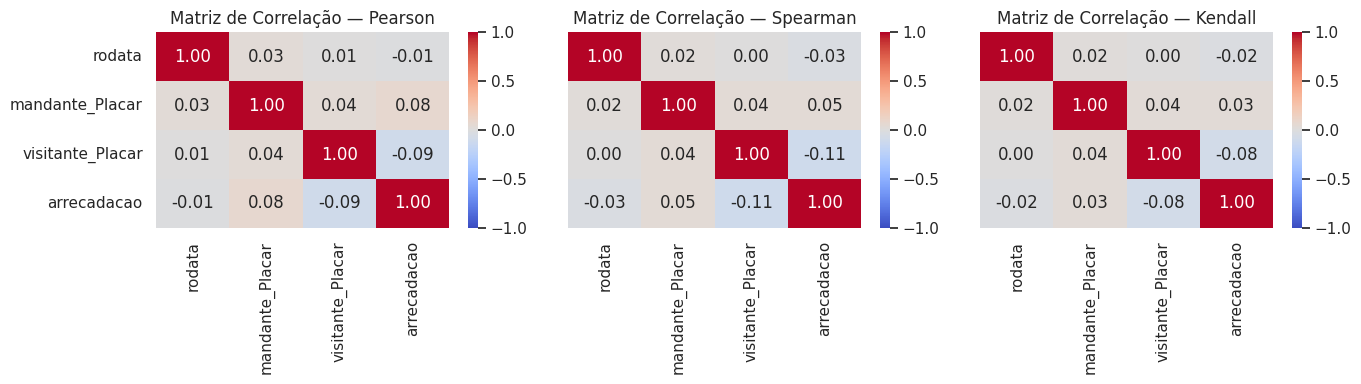

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")

corr_spearman = df[VARS_QUANT].corr(method="spearman")

corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=ax[0]
)

ax[0].set_title("Matriz de Correlação — Pearson")

sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=ax[1]
)

ax[1].set_title("Matriz de Correlação — Spearman")

sns.heatmap(
    corr_kendall,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=ax[2]
)

ax[2].set_title("Matriz de Correlação — Kendall")

plt.tight_layout()
plt.show()


Como os dados do triângulo superior e inferior são simétricos, poderia plotar a matriz de correlação da seguinte forma.

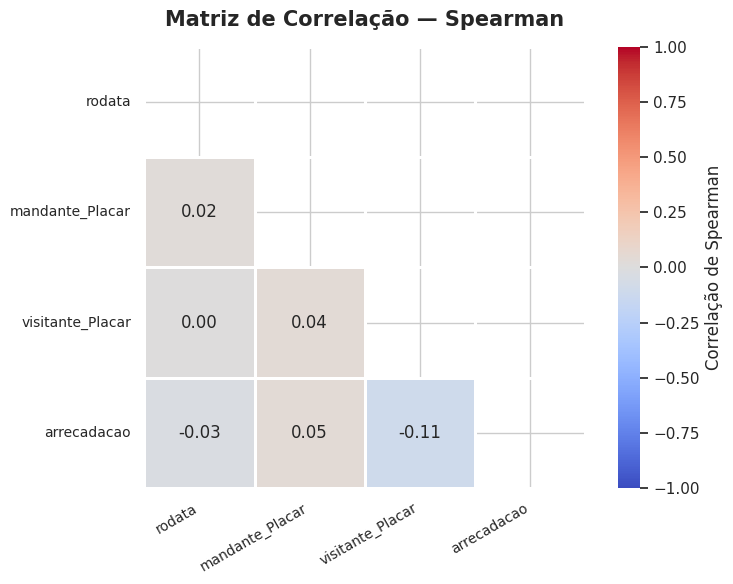

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_spearman,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Correlação de Spearman"},
    annot_kws={"size": 12}
)

plt.title(
    "Matriz de Correlação — Spearman",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=30, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

Pearson e Spearman não apresentaram grandes diferenças entre os pares de variáveis analisados os valores ficaram muito próximos indicando que não existe um sinal claro de relação monotônica não linear e além disso todas as correlações foram fracas e próximas de zero mostrando pouca relação entre as variáveis quantitativas analisadas.

Escolhi arrecadacao x visitante_Placar porque, entre as variáveis quantitativas analisadas, esse par apresentou uma das maiores correlações em módulo. O objetivo é verificar visualmente se existe alguma tendência entre a arrecadação da partida e o número de gols marcados pelo time visitante.

Pra discutir: existe uma tendência visível entre arrecadacao e visitante_Placar? As duas classes de resultado_mandante aparecem separadas no gráfico ou estão bastante misturadas?


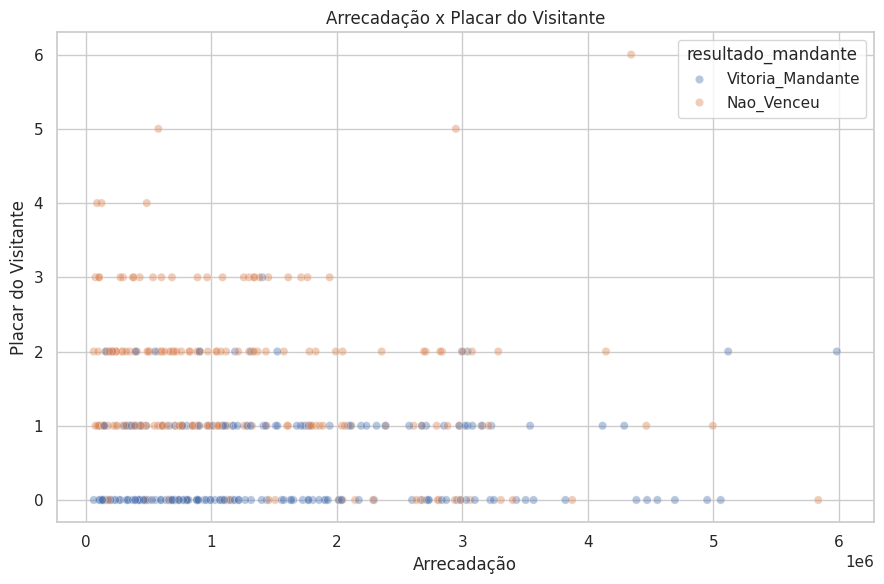

In [ ]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="arrecadacao",
    y="visitante_Placar",
    hue="resultado_mandante",
    alpha=0.4
)

plt.title("Arrecadação x Placar do Visitante")
plt.xlabel("Arrecadação")
plt.ylabel("Placar do Visitante")

plt.tight_layout()
plt.show()


**Pra discutir:** existe uma tendência visível entre `arrecadacao` e `visitante_Placar`? As duas classes de `resultado_mandante` ocupam regiões diferentes do gráfico ou estão misturadas?



A análise do gráfico não mostra uma tendência muito clara entre a arrecadação e o placar do visitante as duas variáveis apresentam uma relação negativa muito fraca conforme a correlação de Spearman de -0,11 e os pontos ficam bastante espalhados pelo gráfico As duas classes de resultado_mandante também aparecem misturadas sem uma separação evidente entre as regiões do gráfico portanto não há uma relação forte entre essas variáveis que permita distinguir claramente os resultados das partidas.

Os dois testes concordam nas variáveis analisadas sendo rodata não significativa e mandante_Placar e visitante_Placar significativas A arrecadacao apresentou resultado NaN e não pôde ser avaliada Como os dados não são normais o Mann-Whitney deve ser priorizado quando houver divergência por respeitar melhor as premissas dos dados

### Justificativa

Não foi realizada a comparação estatística da `arrecadacao` entre os estados do mandante por ANOVA ou Kruskal-Wallis. A variável `arrecadacao` possui muitos valores ausentes, restando apenas 380 registros preenchidos. Ao dividir esses registros entre os estados, alguns grupos ficaram com uma quantidade de observações insuficiente para a realização dos testes, fazendo com que os resultados retornassem `NaN`.

Por isso, optei por não forçar a aplicação dos testes e mantivemos a análise da `arrecadacao` nas etapas descritivas e gráficas, que são mais adequadas para os dados disponíveis.



#### Quantitativa x Qualitativa

Teste Qui-Quadrado
Qui-quadrado = 114.5275
Graus de liberdade = 14
p-valor = 7.375e-18
Conclusão: rejeitamos a hipótese de independência.
Existe associação estatisticamente significativa entre o estado do mandante e o resultado da partida.


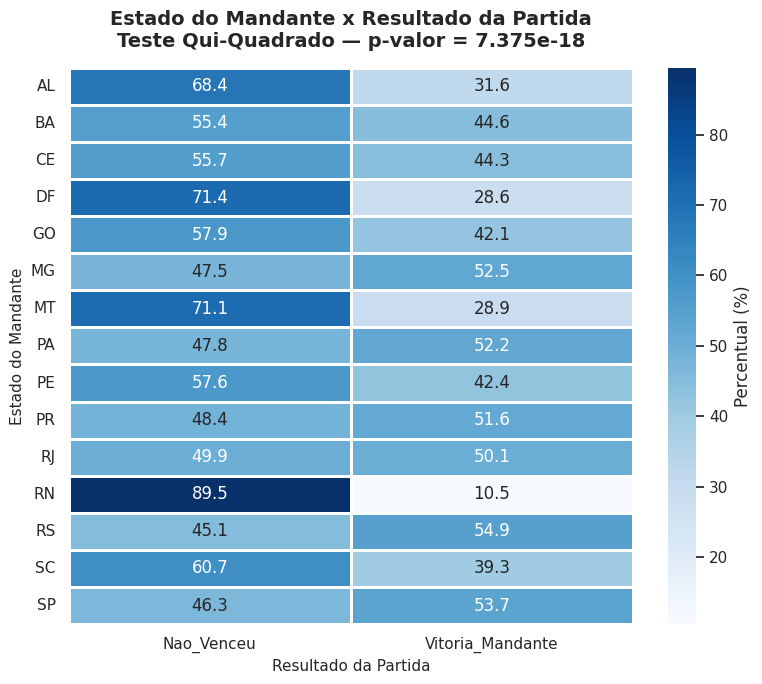

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# 1. Criar a tabela de contingência
tabela_contingencia = pd.crosstab(
    df["mandante_Estado"],
    df["resultado_mandante"]
)

# 2. Aplicar o teste Qui-Quadrado
chi2, p_chi2, graus_liberdade, frequencias_esperadas = chi2_contingency(
    tabela_contingencia
)

# 3. Mostrar os resultados do teste
print("Teste Qui-Quadrado")
print(f"Qui-quadrado = {chi2:.4f}")
print(f"Graus de liberdade = {graus_liberdade}")
print(f"p-valor = {p_chi2:.4g}")

# 4. Interpretar o resultado
if p_chi2 < 0.05:
    print("Conclusão: rejeitei a hipótese de independência.")
    print("Existe associação estatisticamente significativa entre o estado do mandante e o resultado da partida.")
else:
    print("Conclusão: não rejeitei a hipótese de independência.")
    print("Não há evidência suficiente de associação entre o estado do mandante e o resultado da partida.")

# 5. Criar tabela percentual para o gráfico
contingencia_estado = pd.crosstab(
    df["mandante_Estado"],
    df["resultado_mandante"],
    normalize="index"
) * 100

# 6. Criar o gráfico
plt.figure(figsize=(8, 7))

sns.heatmap(
    contingencia_estado,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Percentual (%)"}
)

# 7. Título com o p-valor
plt.title(
    f"Estado do Mandante x Resultado da Partida\n"
    f"Teste Qui-Quadrado — p-valor = {p_chi2:.4g}",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xlabel("Resultado da Partida", fontsize=11)
plt.ylabel("Estado do Mandante", fontsize=11)

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

Pra discutir: o p-valor do teste Qui-Quadrado indica que mandante_Estado e resultado_mandante são independentes, ou existe uma associação estatisticamente significativa entre essas variáveis?

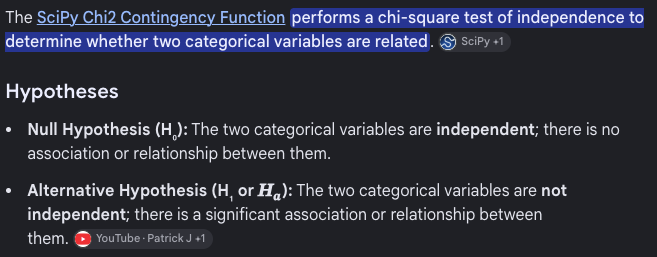

Pra discutir: o p-valor do teste Qui-Quadrado é muito menor que 0,05, portanto rejeitei a hipótese de independência. Existe uma associação estatisticamente significativa entre o estado do mandante e o resultado da partida. Isso indica que o resultado das partidas não é totalmente independente do estado onde o time mandante está localizado.

In [ ]:
def metrica_desbalanceamento(serie):
    proporcoes = serie.value_counts(normalize=True)

    return proporcoes.round(3)


print("Desbalanceamento — resultado da partida:")

print(metrica_desbalanceamento(df["resultado_mandante"]))

prop_por_estado = pd.crosstab(
    df["mandante_Estado"],
    df["resultado_mandante"],
    normalize="index"
).round(3)

prop_por_estado

Desbalanceamento — resultado da partida:
resultado_mandante
Nao_Venceu          0.504
Vitoria_Mandante    0.496
Name: proportion, dtype: float64


resultado_mandante,Nao_Venceu,Vitoria_Mandante
mandante_Estado,,
AL,0.684,0.316
BA,0.554,0.446
CE,0.557,0.443
DF,0.714,0.286
GO,0.579,0.421
MG,0.475,0.525
MT,0.711,0.289
PA,0.478,0.522
PE,0.576,0.424


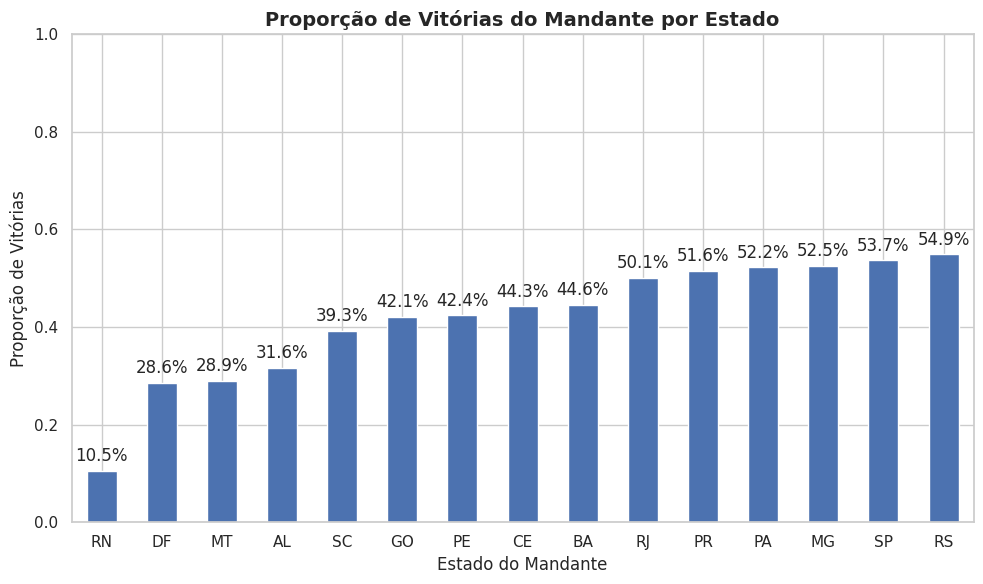

In [ ]:
proporcao_vitoria = (
    df.groupby("mandante_Estado")["resultado_mandante"]
    .apply(lambda x: (x == "Vitoria_Mandante").mean())
    .sort_values()
)

plt.figure(figsize=(10, 6))

ax = proporcao_vitoria.plot(kind="bar")

plt.title(
    "Proporção de Vitórias do Mandante por Estado",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Estado do Mandante")
plt.ylabel("Proporção de Vitórias")
plt.ylim(0, 1)

plt.xticks(rotation=0)

for i, valor in enumerate(proporcao_vitoria):
    ax.text(
        i,
        valor + 0.02,
        f"{valor:.1%}",
        ha="center"
    )

plt.tight_layout()
plt.show()

Pra discutir: a proporção de vitórias do mandante varia entre os estados? Essas diferenças podem estar relacionadas a características reais do futebol em cada estado como força dos times mando de campo e quantidade de partidas ou podem refletir diferenças na composição da base Portanto é importante observar se o desfecho se distribui de forma semelhante entre os diferentes grupos antes de realizar uma modelagem

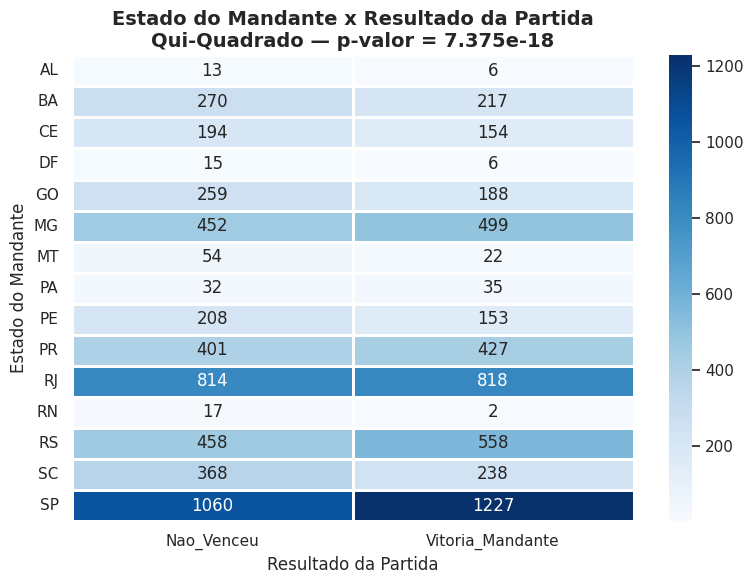

In [ ]:
contingencia = pd.crosstab(
    df["mandante_Estado"],
    df["resultado_mandante"]
)

chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

plt.figure(figsize=(8, 6))

sns.heatmap(
    contingencia,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    linecolor="white"
)

plt.title(
    f"Estado do Mandante x Resultado da Partida\n"
    f"Qui-Quadrado — p-valor = {p_valor:.4g}",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Resultado da Partida")
plt.ylabel("Estado do Mandante")

plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


Pra discutir: o teste Qui-Quadrado indica uma associação estatisticamente significativa entre o estado do mandante e o resultado da partida. Porém, esse resultado não explica por que essa associação existe. Ela pode estar relacionada a diferenças reais entre os estados, como desempenho dos times e mando de campo, ou a características da própria composição da base. O teste estatístico mostra que existe associação, mas não permite afirmar que uma variável é a causa da outra.

#### Outliers bivariados

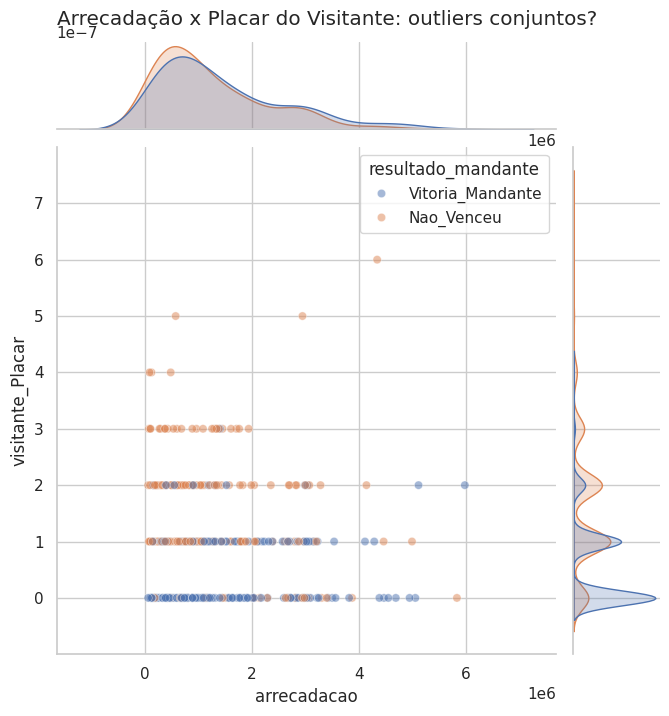

In [ ]:
sns.jointplot(
    data=df,
    x="arrecadacao",
    y="visitante_Placar",
    hue="resultado_mandante",
    alpha=0.5,
    height=7
)

plt.suptitle(
    "Arrecadação x Placar do Visitante: outliers conjuntos?",
    y=1.02
)

plt.show()

Pra discutir: existe algum ponto que não parecia ser um outlier quando as variáveis foram analisadas separadamente, mas que se destaca no gráfico por apresentar uma combinação incomum de arrecadacao e visitante_Placar? Esse tipo de análise é importante porque um valor pode não ser extremo em nenhuma variável isoladamente, mas ainda assim representar uma combinação pouco comum entre as duas variáveis.

#### Análise Multivariada

##### Matriz de Correlação

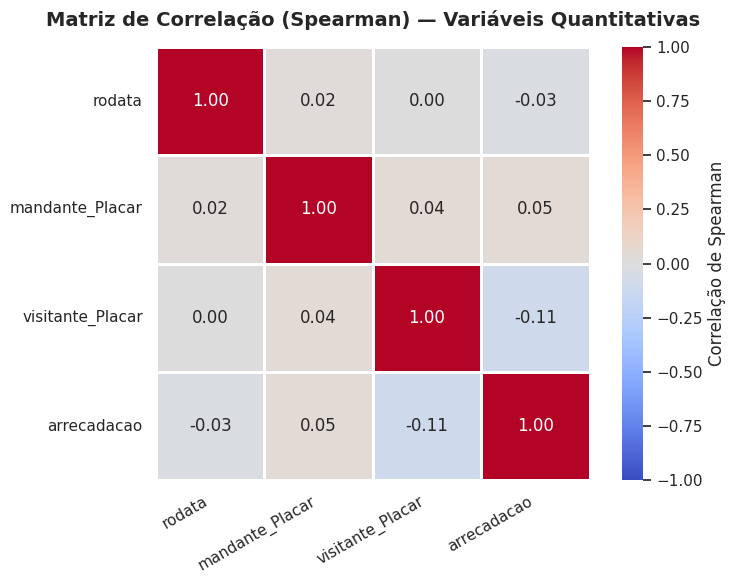

In [ ]:
corr_spearman = df[VARS_QUANT].corr(method="spearman")

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Correlação de Spearman"}
)

plt.title(
    "Matriz de Correlação (Spearman) — Variáveis Quantitativas",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

##### Correlograma

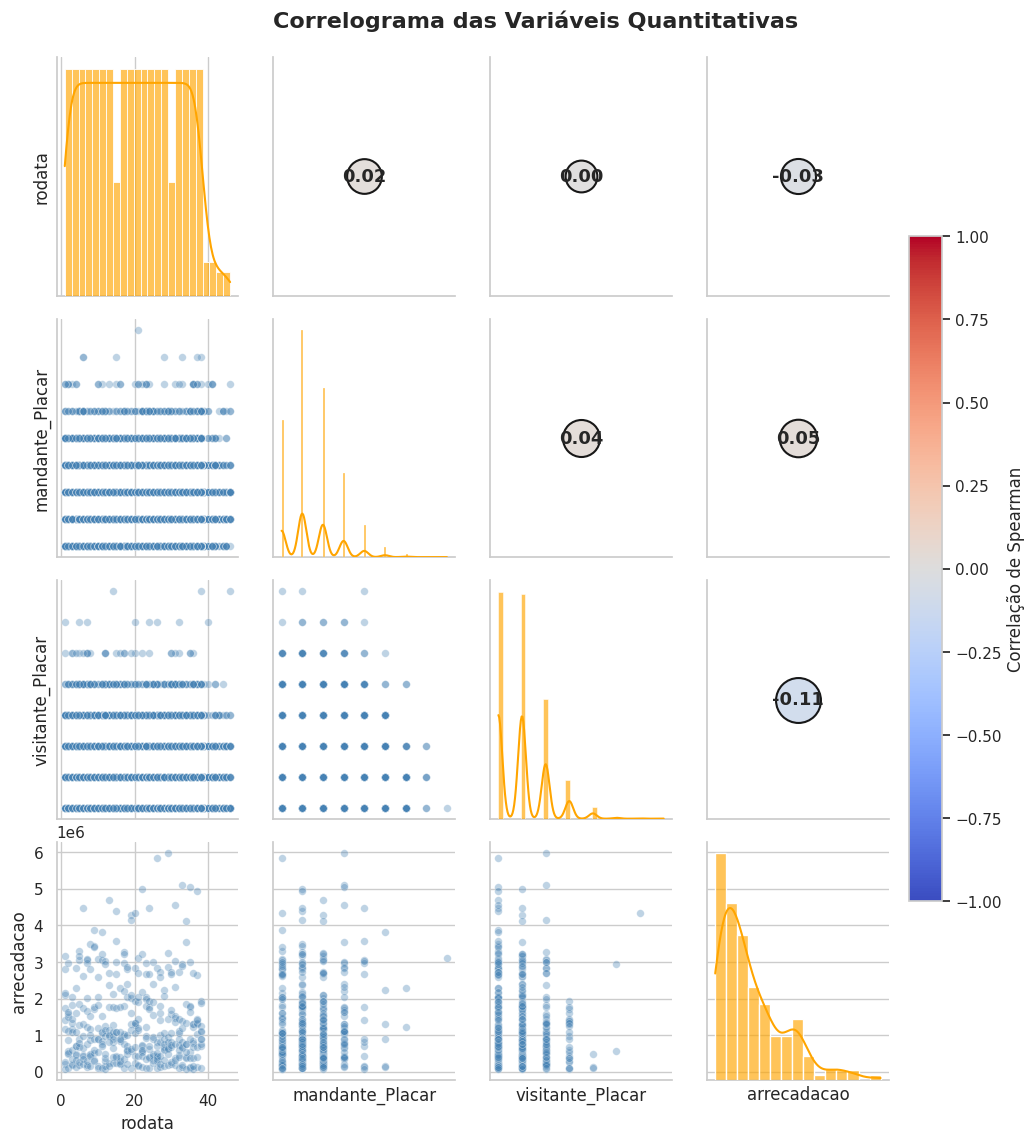

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = pd.Series(x).corr(pd.Series(y), method="spearman")

    ax = plt.gca()

    # Define tamanho mínimo para correlações fracas
    tamanho = 500 + abs(r) * 5000

    ax.scatter(
        0.5,
        0.5,
        s=tamanho,
        c=[r],
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        transform=ax.transAxes,
        edgecolor="black",
        linewidth=1.5,
        alpha=0.9
    )

    ax.text(
        0.5,
        0.5,
        f"{r:.2f}",
        transform=ax.transAxes,
        ha="center",
        va="center",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)


g = sns.PairGrid(
    df[VARS_QUANT],
    diag_sharey=False,
    height=2.8
)

# Parte inferior: dispersão
g.map_lower(
    sns.scatterplot,
    color="steelblue",
    alpha=0.35,
    s=30
)

# Diagonal: distribuição
g.map_diag(
    sns.histplot,
    color="orange",
    kde=True,
    alpha=0.65
)

# Parte superior: correlação
g.map_upper(circulo_correlacao)

# Barra de cores
sm = ScalarMappable(
    norm=Normalize(-1, 1),
    cmap="coolwarm"
)

sm.set_array([])

g.fig.colorbar(
    sm,
    ax=g.axes,
    shrink=0.65,
    pad=0.02,
    label="Correlação de Spearman"
)

# Título
g.fig.suptitle(
    "Correlograma das Variáveis Quantitativas",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.show()

Nenhuma correlação apresentou força suficiente para sugerir redundância entre as variáveis. Todas as correlações foram fracas ou praticamente inexistentes, com valores de |r| menores que 0,3. A maior correlação em módulo foi entre visitante_Placar e arrecadacao, com aproximadamente -0,11, ainda considerada fraca. Portanto, não há evidências de que alguma das variáveis quantitativas seja redundante em relação às outras.


## Conclusão!

Ao longo da análise da base do Campeonato Brasileiro, foi possível observar que as variáveis quantitativas apresentam comportamentos diferentes. A `rodata` possui uma distribuição mais equilibrada, enquanto os placares de mandante e visitante apresentam assimetria positiva devido à ocorrência de alguns placares elevados. A `arrecadacao` também apresenta assimetria positiva e possui muitos valores ausentes, com apenas 380 registros preenchidos.

Os testes de normalidade indicaram que as variáveis quantitativas não seguem uma distribuição normal. Porém, como a base possui 9.165 partidas, considerei também os histogramas, o QQ-Plot e as medidas de assimetria para interpretar esses resultados, já que o teste de Shapiro-Wilk pode ser muito sensível em amostras grandes.

Na análise dos dados ausentes, identifiquei valores faltantes principalmente nas colunas de formação, técnicos e arrecadação. As colunas `formacao_mandante` e `formacao_visitante` possuem 4.975 valores ausentes cada uma e essas ausências acontecem juntas nas mesmas partidas. Por isso, não é possível determinar apenas com essa análise se o mecanismo é MCAR, MAR ou MNAR. Para as formações, substituí os valores ausentes por `"Nao informado"` para evitar a perda de uma grande quantidade de partidas.

Na análise de outliers, identifiquei valores estatisticamente extremos principalmente nos placares e na `arrecadacao`. Porém, esses valores são possíveis dentro do contexto das partidas, então optei por mantê-los em vez de removê-los sem evidência de que fossem erros. A transformação logarítmica da `arrecadacao` também foi testada e reduziu bastante a assimetria, mas a variável original foi mantida.

Nas análises de correlação, Pearson, Spearman e Kendall apresentaram resultados próximos e todas as correlações foram fracas. A maior correlação em módulo foi entre `visitante_Placar` e `arrecadacao`, com aproximadamente -0,11. Portanto, não encontrei evidências de uma relação forte ou de redundância entre as variáveis quantitativas.

Por fim, o teste Qui-Quadrado foi utilizado para verificar a relação entre `mandante_Estado` e `resultado_mandante`. O resultado apresentou um p-valor menor que 0,05, indicando uma associação estatisticamente significativa entre essas variáveis. Essa associação, porém, não significa que uma variável seja necessariamente a causa da outra.

De forma geral, a análise mostrou que a base possui dados faltantes e alguns valores extremos que precisam ser considerados na interpretação dos resultados. Também foi possível identificar padrões nas distribuições, nas correlações e na relação entre o estado do mandante e o resultado das partidas.

Nesta atividade, utilizei IA generativa como apoio em pontos pontuais do processo: para corrigir erros e
ajustes em trechos de código que não estavam funcionando como esperado, para melhorar a visualização de
alguns gráficos (ajustes de cores, títulos, legendas e layout), e para revisar erros de português que eu
digitei errado ao longo do texto. Todas as interpretações dos resultados, as decisões de tratamento dos
dados e as conclusões da análise foram feitas e revisadas por mim.